AF 7-2025

# Redo

* Amount of time that different age groups are spending alone (not including attending classes or work)
* For those under 35, broken out by activity category 
* Leisure time has been flat over time. 
* For leisure, broken out by specific activity over time
* Total video gaming time, total video gaming time alone (by gender -- but mostly just focused on boys.)

In [1]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import datetime
from matplotlib import colormaps

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

source = "..//data//source//"
processed = "..//data//processed//"

long_glob = glob.glob(processed + "0324//atus*.csv")
print(long_glob)

a = {}

for path in long_glob: 

    name = path.split("/")[-1][4:-9]

    a[name] = pd.read_csv(path)

['..//data//processed//0324/atussum-0324.csv', '..//data//processed//0324/atusresp-0324.csv', '..//data//processed//0324/atusact-0324.csv', '..//data//processed//0324/atuscps-0324.csv', '..//data//processed//0324/atusrost-0324.csv', '..//data//processed//0324/atuswho-0324.csv']


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_3714/291017233.py:26: DtypeWarning: Columns (25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  a[name] = pd.read_csv(path)


In [2]:
# PASTE THE GROUPBY FUNCTION 
activity_code_vars = ['TRCODEP', 'TRTIER1P', 'TRTIER2P']

def weighted_average_pivot(df, df_resp, weight_column, year_col, other_weighted_group_cols, group_cols, agg_col): 

    # get the total of the weights by group 
    weighted_group_cols = year_col + other_weighted_group_cols
    weights_by_group = df_resp.groupby(weighted_group_cols)[weight_column].agg(['sum', 'count']).reset_index()
    
    # get the weighted sum for each group
    groupby_cols = weighted_group_cols + group_cols
    avg_by_code = df.groupby(groupby_cols)[[agg_col, weight_column]].apply(lambda a: sum(a[agg_col] * a[weight_column]) * 7/60).reset_index()

    # merge and divide out to get the averages
    abc_w = pd.merge(avg_by_code, weights_by_group, on = weighted_group_cols, how = 'left', validate='m:1')
    abc_w['avg_min_weighted'] = abc_w[0]/abc_w['sum']

    act_avg_pivot = abc_w.pivot_table(index = group_cols + other_weighted_group_cols, columns=year_col, values='avg_min_weighted', aggfunc='mean').reset_index()
    act_avg_pivot['raw_change'] = act_avg_pivot[2024]-act_avg_pivot[2004]

    return act_avg_pivot


In [ ]:
sum_variables = ["TUCASEID", # ID
                 "TUYEAR", # Year
                "TESCHENR", # School enrollment
                "TRSPPRES", # Presence of spouse
                "TUDIARYDAY", # day of week
                "TESEX", # Sex
                "TRERNWA", # Weekly earnings 
                "TEHRUSLT", # Usual weekly hours of work 
                "TESCHLVL", # school level
                "TUFNWGTP", # Weight
                "TEAGE", # Age 
                "PTDTRACE", # Race
                "PEHSPNON", # Hispanic Origin
                "PEEDUCA", # Educational attainment
                "GTMETSTA", # new metro status
                "GEMETSTA" # old metro status
]

actsum = a['sum'][sum_variables]
actsum = actsum[(actsum.TUYEAR>=2004) & (actsum.TEAGE <35)]

SAMPLE_IDS = actsum.TUCASEID.unique()
print(len(SAMPLE_IDS))

actsum.head()

58292


,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA
20721,20040101040060,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1
20722,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1
20723,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1
20732,20040101040589,2004,2,1,1,2,-1,5,-1,1.923224e+06,25,1,2,40,-1,1
20736,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1


In [4]:
resp = a['resp'][['TUCASEID', 'TRTALONE']]
resp = resp[resp.TUCASEID.isin(SAMPLE_IDS)]
print(resp.shape)
resp.head()

(58292, 2)


,TUCASEID,TRTALONE
20721,20040101040060,120
20722,20040101040079,125
20723,20040101040080,47
20732,20040101040589,15
20736,20040101040601,330


In [5]:
sum_resp = pd.merge(actsum, resp, on = 'TUCASEID', how = 'outer', validate = "1:1")
print(sum_resp.shape)
sum_resp.head()

(58292, 17)


,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,TRTALONE
0,20040101040060,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,120
1,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1,125
2,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1,47
3,20040101040589,2004,2,1,1,2,-1,5,-1,1.923224e+06,25,1,2,40,-1,1,15
4,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,330


In [6]:
sum_resp.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index().pivot_table(index = "TUYEAR", columns = "TESEX", values = 0, aggfunc= 'mean').T

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_3714/3340480651.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sum_resp.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index().pivot_table(index = "TUYEAR", columns = "TESEX", values = 0, aggfunc= 'mean').T


TUYEAR,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
TESEX,,,,,,,,,,,,,,,,,,,,,
1,235.761404,227.534444,227.827757,238.808299,219.730538,236.990726,242.130109,234.104601,240.490259,245.539082,231.132667,245.234137,255.032219,249.078755,276.592847,275.741355,318.052017,311.312510,307.165216,314.940308,304.821680
2,212.893918,194.374374,188.183785,198.428617,210.566942,198.594364,192.106709,196.874125,191.995983,190.811559,203.765016,209.009245,215.389695,200.468210,206.104864,221.512736,229.055046,276.743957,238.156525,248.603126,250.200599


In [ ]:
# now let's do the same thing but using the activity data

act = a['act'][['TUCASEID', 'TUACTIVITY_N', 'TUACTDUR24', 'TUSTARTTIM', 'TUSTOPTIME', 'TRCODEP', 'TRTIER1P', 'TRTIER2P', 'TUACTDUR24', 'TUACTDUR']]
act = act.loc[:,~act.columns.duplicated()].copy()
act = act[act.TUCASEID.isin(SAMPLE_IDS)]

act['TUSTARTTIM'] = pd.to_datetime(a['act']['TUSTARTTIM'], format = "%H:%M:%S")
act['TUSTOPTIME'] = pd.to_datetime(a['act']['TUSTOPTIME'], format = "%H:%M:%S")

# if stop time is before start time, then add a day 
act.loc[act.TUSTOPTIME < act.TUSTARTTIM, 'TUSTOPTIME'] = act.loc[act.TUSTOPTIME < act.TUSTARTTIM, 'TUSTOPTIME'].apply(lambda x: x + datetime.timedelta(days = 1))

# unless it's the first activity and it starts before 4AM, then add a day 

act.loc[(act.TUACTIVITY_N!=1) & (act.TUSTARTTIM<datetime.datetime(1900,1,1,4,0,0)), 'TUSTARTTIM'] = act.loc[(act.TUACTIVITY_N!=1) & (act.TUSTARTTIM<datetime.datetime(1900,1,1,4,0,0)), 'TUSTARTTIM'].apply(lambda x: x + datetime.timedelta(days = 1))
act.loc[(act.TUACTIVITY_N!=1) & (act.TUSTARTTIM>=datetime.datetime(1900,1,2,0,0,0)), 'TUSTOPTIME'] = act.loc[(act.TUACTIVITY_N!=1) & (act.TUSTARTTIM>=datetime.datetime(1900,1,2,0,0,0)), 'TUSTOPTIME'].apply(lambda x: x + datetime.timedelta(days = 1))


act.head(100).tail(50)

In [8]:
# find the alone activities -- dropping all the cases with multiple people, but that doesn't seem to affect our sample
print(a['who'].shape)
who = a['who'].drop_duplicates(['TUCASEID', 'TUACTIVITY_N'], keep=False)
who = who[who.TUCASEID.isin(SAMPLE_IDS)]
print(who.shape)

who_alone = who[((who.TUWHO_CODE==18)| (who.TUWHO_CODE==19))].drop(['TULINENO', 'TRWHONA', 'TUWHO_CODE'], axis =1)
who_alone = who_alone[who_alone.TUCASEID.isin(SAMPLE_IDS)]
who_alone['alone'] = 1
print(who_alone.shape)

who_alone.head()

(6221596, 5)
(845397, 5)
(304321, 3)


,TUCASEID,TUACTIVITY_N,alone
526568,20040101040060,6,1
526584,20040101040079,2,1
526585,20040101040079,3,1
526586,20040101040079,4,1
526587,20040101040079,5,1


In [9]:
a['who'].head()

,TUCASEID,TULINENO,TUACTIVITY_N,TRWHONA,TUWHO_CODE
0,20030100013280,1,1,0,18
1,20030100013280,-1,2,1,-1
2,20030100013280,-1,3,1,-1
3,20030100013280,1,4,0,18
4,20030100013280,2,5,0,20


In [10]:
act_who = pd.merge(act, who_alone, on = ['TUCASEID', 'TUACTIVITY_N'], how = 'outer', validate = '1:1')
act_who.alone = act_who.alone.fillna(0)
act_who.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone
0,20040101040060,1,90,1900-01-01 04:00:00,1900-01-01 05:30:00,120303,12,1203,90,0.0
1,20040101040060,2,390,1900-01-01 05:30:00,1900-01-01 12:00:00,10101,1,101,390,0.0
2,20040101040060,3,90,1900-01-01 12:00:00,1900-01-01 13:30:00,10201,1,102,90,0.0
3,20040101040060,4,30,1900-01-01 13:30:00,1900-01-01 14:00:00,20101,2,201,30,0.0
4,20040101040060,5,120,1900-01-01 14:00:00,1900-01-01 16:00:00,120101,12,1201,120,0.0


In [11]:
# let's take out the alone flag for school (060101) and for work (0501)

act_who.loc[act_who.TRCODEP == 60101, 'alone'] = 0
act_who.loc[act_who.TRTIER2P == 501, 'alone'] = 0

In [12]:
# merge in weights 

act_who_sum = pd.merge(act_who, actsum, on = 'TUCASEID', how = 'outer', validate = "m:1")
act_who_sum.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA
0,20040101040060,1,90,1900-01-01 04:00:00,1900-01-01 05:30:00,120303,12,1203,90,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1
1,20040101040060,2,390,1900-01-01 05:30:00,1900-01-01 12:00:00,10101,1,101,390,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1
2,20040101040060,3,90,1900-01-01 12:00:00,1900-01-01 13:30:00,10201,1,102,90,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1
3,20040101040060,4,30,1900-01-01 13:30:00,1900-01-01 14:00:00,20101,2,201,30,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1
4,20040101040060,5,120,1900-01-01 14:00:00,1900-01-01 16:00:00,120101,12,1201,120,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1


In [13]:
agg_by_id = act_who_sum[act_who_sum.alone==1].groupby(['TUCASEID', 'TUYEAR', 'TUFNWGTP', 'TESEX'])[['TUACTDUR24', 'TUACTDUR']].sum().reset_index()
agg_by_id.head()

,TUCASEID,TUYEAR,TUFNWGTP,TESEX,TUACTDUR24,TUACTDUR
0,20040101040060,2004,6.181583e+06,2,120,120
1,20040101040079,2004,7.423105e+06,1,125,125
2,20040101040080,2004,1.213356e+07,1,47,47
3,20040101040589,2004,1.923224e+06,2,15,15
4,20040101040601,2004,1.719568e+06,1,330,330


<Axes: xlabel='TUYEAR'>

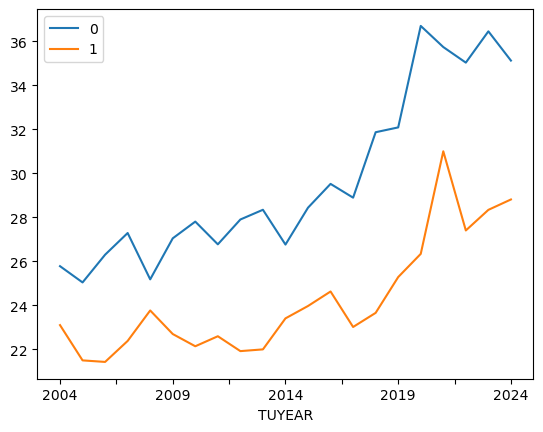

In [14]:
weighted_average_pivot(act_who_sum[act_who_sum.alone==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], [], 'TUACTDUR24').drop(['TESEX', 'raw_change'], axis =1).T.plot()

## checking to see how well the #s align

In [15]:
alone_merge = pd.merge(agg_by_id, resp, on = ['TUCASEID'], how = 'left', validate = "1:1")
alone_merge.head()

,TUCASEID,TUYEAR,TUFNWGTP,TESEX,TUACTDUR24,TUACTDUR,TRTALONE
0,20040101040060,2004,6.181583e+06,2,120,120,120
1,20040101040079,2004,7.423105e+06,1,125,125,125
2,20040101040080,2004,1.213356e+07,1,47,47,47
3,20040101040589,2004,1.923224e+06,2,15,15,15
4,20040101040601,2004,1.719568e+06,1,330,330,330


In [16]:
alone_merge['equal'] = (alone_merge.TUACTDUR24==alone_merge.TRTALONE)
alone_merge['equal'].value_counts()

equal
True     51289
False      803
Name: count, dtype: int64

## look closely at social activities and the categories

In [17]:
# add social flag
# code the social flag

TRTIER1P_codes = {18: "Travelling",
4:	"Caring for & helping non HH members",
7:	"Consumer Purchases",
1:	"Personal Care",
10:	"Government Services & Civic Obligations",
9:	"Household Services",
14:	"Religious and spiritual activities",
15:	"Volunteer Activities",
5:	"Work & Work-Related Activities",
8:	"Professional & Personal Care Services",
3:	"Caring for & Helping household members",
50:	"Data Codes",
16:	"Telephone Calls",
11:	"Eating and Drinking",
6:	"Education",
13: "Sports, Exercise, and Recreation",
2:	"Household Activities",
12:	"Socializing, Relaxing, and Leisure"}

act_who_sum['social'] = 0
act_who_sum['description'] = act_who_sum['TRTIER1P'].replace(TRTIER1P_codes)

# code all the descriptions 

In [18]:
# 12 -- Socializing, Relaxing, and Leisure
act_who_sum.loc[act_who_sum.TRTIER1P == 12, 'social'] = 1
act_who_sum.loc[act_who_sum.TRTIER1P == 12, 'description'] = "Other socializing, relaxing and Leisure"

act_who_sum.loc[act_who_sum.TRCODEP == 120101, 'description'] = "Socializing and Communicating"
act_who_sum.loc[act_who_sum.TRTIER2P == 1202, 'description'] = "Attending or Hosting Social Events"
act_who_sum.loc[act_who_sum.TRCODEP == 120303, 'description'] = "Television and movies"
act_who_sum.loc[act_who_sum.TRCODEP == 120304, 'description'] = "Television and movies"
act_who_sum.loc[act_who_sum.TRCODEP == 120306, 'description'] = "Listening to/playing music (not radio)"
act_who_sum.loc[act_who_sum.TRCODEP == 120307, 'description'] = "Playing games"
act_who_sum.loc[act_who_sum.TRCODEP == 120308, 'description'] = "Computer use for leisure (exc. Games)"
act_who_sum.loc[act_who_sum.TRCODEP == 120309, 'description'] = "Arts and crafts as a hobby"
act_who_sum.loc[act_who_sum.TRCODEP == 120312, 'description'] = "Reading for personal interest"
act_who_sum.loc[act_who_sum.TRCODEP == 120301, 'description'] = "Relaxing, thinking"
act_who_sum.loc[act_who_sum.TRCODEP == 120302, 'description'] = "Tobacco and drug use"
act_who_sum.loc[act_who_sum.TRCODEP == 120305, 'description'] = "Listening to the radio"
act_who_sum.loc[act_who_sum.TRCODEP == 120401, 'description'] = "Attending performing arts"
act_who_sum.loc[act_who_sum.TRCODEP == 120403, 'description'] = "Attending movies/film"
act_who_sum.loc[act_who_sum.TRCODEP == 120499, 'description'] = "Other Arts and entertainment"

# 1301 -- Participating in Sports, Exercise, or Recreation 
act_who_sum.loc[act_who_sum.TRTIER2P == 1301, 'social'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 1301, 'description'] = "Participating in Sports, Exercise, or Recreation"

# 1302 -- Attending Sporting/Recreational Events 
act_who_sum.loc[act_who_sum.TRTIER2P == 1302, 'social'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 1302, 'description'] = "Attending Sporting/Recreational Events"

# 15 -- Volunteer Activities
act_who_sum.loc[act_who_sum.TRTIER1P == 15, 'social'] = 1
act_who_sum.loc[act_who_sum.TRTIER1P == 15, 'description'] = "Volunteer Activities"

# 0206 -- pet care
act_who_sum.loc[act_who_sum.TRTIER2P == 206, 'social'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 206, 'description'] = "Animals and Pets"

# 160102 -- telephone calls to/from friends, neighbors, or acquaintances 
act_who_sum.loc[act_who_sum.TRCODEP == 160102, 'social'] = 1
act_who_sum.loc[act_who_sum.TRCODEP == 160102, 'description'] = "Telephone calls to/from friends, neighbors, or acquaintances"

act_who_sum['plot_label'] = act_who_sum['TRTIER1P'].astype(str) + "_" + act_who_sum['description']

In [19]:
act_who_sum.plot_label.value_counts(dropna=False)

plot_label
18_Travelling                                                      235086
1_Personal Care                                                    207877
2_Household Activities                                             112499
11_Eating and Drinking                                             110074
3_Caring for & Helping household members                            91110
12_Television and movies                                            77673
5_Work & Work-Related Activities                                    53756
7_Consumer Purchases                                                37167
12_Socializing and Communicating                                    34884
6_Education                                                         21003
13_Participating in Sports, Exercise, or Recreation                 16078
12_Relaxing, thinking                                               11696
12_Playing games                                                    11207
4_Caring for & helping non 

In [20]:
with pd.ExcelWriter(processed + 'nb_3_alone_hours_per_week_by_sex.xlsx') as writer:

    for var in activity_code_vars: 

        f = weighted_average_pivot(act_who_sum[act_who_sum.alone==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], [var], 'TUACTDUR24')

        f.to_excel(writer, sheet_name = var, index =None)

In [73]:
by_label = weighted_average_pivot(act_who_sum[act_who_sum.alone==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['plot_label'], 'TUACTDUR24')
by_label.to_csv(processed + "nb_3_sex_by_plot_label_alone.csv", index=None)

In [72]:
by_label = weighted_average_pivot(act_who_sum, sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['plot_label'], 'TUACTDUR24')
by_label.to_csv(processed + "nb_3_sex_by_plot_label_not_alone.csv", index=None)

In [ ]:
with pd.ExcelWriter(processed + 'nb_3_assorted.xlsx') as writer:

    f = weighted_average_pivot(act_who_sum[act_who_sum.alone==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['TRTIER1P'], 'TUACTDUR24')
    outfile = f.pivot_table(index = 'TRTIER1P', columns = 'TESEX', values = 'raw_change').reset_index()
    outfile.to_excel(writer, sheet_name = 'TRTIER1P_alone', index =None)

    f = weighted_average_pivot(act_who_sum[act_who_sum.social==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['description'], 'TUACTDUR24')
    outfile = f.pivot_table(index = 'description', columns = 'TESEX', values = 'raw_change').reset_index()
    outfile.to_excel(writer, sheet_name = 'social', index =None)

    f = weighted_average_pivot(act_who_sum[(act_who_sum.social==1) & (act_who_sum.alone==1)], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['description'], 'TUACTDUR24')
    outfile = f.pivot_table(index = 'description', columns = 'TESEX', values = 'raw_change').reset_index()
    outfile.to_excel(writer, sheet_name = 'social_alone', index =None)

In [22]:
# total time gaming, total time gaming alone
gaming = act_who_sum[act_who_sum.description == "Playing games"]
gaming_total = weighted_average_pivot(gaming, sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], [], 'TUACTDUR24').set_index('TESEX').drop(['raw_change'], axis =1).T
gaming_total.columns = ['gaming_M_total', 'gaming_F_total']

gaming_a = gaming[gaming.alone==1]
gaming_alone = weighted_average_pivot(gaming_a, sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], [], 'TUACTDUR24').set_index('TESEX').drop(['raw_change'], axis =1).T
gaming_alone.columns = ['gaming_M_alone', 'gaming_F_alone']
gaming_alone.head()

g = pd.merge(gaming_total, gaming_alone, left_index=True, right_index=True).sort_index(axis=1, ascending=False)
g['gaming_M_with_others'] = g.gaming_M_total - g.gaming_M_alone
g['gaming_F_with_others'] = g.gaming_F_total - g.gaming_F_alone

In [23]:
gaming = act_who_sum[act_who_sum.description == "Television and movies"]
gaming_total = weighted_average_pivot(gaming, sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], [], 'TUACTDUR24').set_index('TESEX').drop(['raw_change'], axis =1).T
gaming_total.columns = ['tv_M_total', 'tv_F_total']

gaming_a = gaming[gaming.alone==1]
gaming_alone = weighted_average_pivot(gaming_a, sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], [], 'TUACTDUR24').set_index('TESEX').drop(['raw_change'], axis =1).T
gaming_alone.columns = ['tv_M_alone', 'tv_F_alone']
gaming_alone.head()

t = pd.merge(gaming_total, gaming_alone, left_index=True, right_index=True).sort_index(axis=1, ascending=False)
t['tv_M_with_others'] = t.tv_M_total - t.tv_M_alone
t['tv_F_with_others'] = t.tv_F_total - t.tv_F_alone

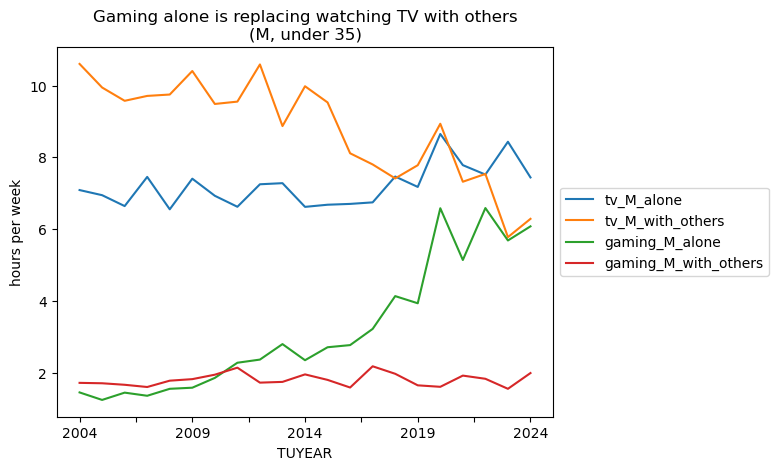

In [24]:
final = pd.merge(g, t, left_index=True, right_index=True)

final[['tv_M_alone', 'tv_M_with_others', 'gaming_M_alone', 'gaming_M_with_others']].plot()
plt.title("Gaming alone is replacing watching TV with others\n(M, under 35)")
plt.ylabel("hours per week")
plt.legend(loc="center left", bbox_to_anchor = (1,0.5))

We've swapped watching TV with friends with gaming alone -- but is the gaming really alone? And is it really worse? 

boys are watching tv alone probably the same amount, and gaming with friends the same amount. 

but instead of watching TV with friends, they're playing games alone

In [25]:
act_who_sum[act_who_sum.description == "Television and movies"].tail()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,social,description,plot_label
1109032,20241212241381,4,240,1900-01-01 18:00:00,1900-01-01 22:00:00,120303,12,1203,240,0.0,2024,2,1,4,1,220000,35,-1,1.504985e+07,26,1,2,46,1,-1,1,Television and movies,12_Television and movies
1109038,20241212241772,5,260,1900-01-01 11:40:00,1900-01-01 16:00:00,120303,12,1203,260,0.0,2024,2,3,7,1,-1,-1,-1,1.161610e+07,25,1,2,43,1,-1,1,Television and movies,12_Television and movies
1109053,20241212242171,8,150,1900-01-01 16:30:00,1900-01-01 19:00:00,120303,12,1203,150,0.0,2024,2,1,6,1,36600,10,-1,1.210722e+07,28,1,2,44,1,-1,1,Television and movies,12_Television and movies
1109056,20241212242171,11,60,1900-01-01 20:00:00,1900-01-01 21:00:00,120303,12,1203,60,0.0,2024,2,1,6,1,36600,10,-1,1.210722e+07,28,1,2,44,1,-1,1,Television and movies,12_Television and movies
1109068,20241212242212,10,112,1900-01-01 18:08:00,1900-01-01 20:00:00,120303,12,1203,112,0.0,2024,2,3,1,2,111600,40,-1,8.531420e+06,27,4,2,43,1,-1,1,Television and movies,12_Television and movies


In [26]:
# can't use the "who" variable because i dropped duplicates there but can access the data directly. 
a['who'][a['who'].TUCASEID==20241211242061].tail()

,TUCASEID,TULINENO,TUACTIVITY_N,TRWHONA,TUWHO_CODE
6219113,20241211242061,2,32,0,20
6219114,20241211242061,2,33,0,20
6219115,20241211242061,2,34,0,20
6219116,20241211242061,2,35,0,20
6219117,20241211242061,-1,36,1,-1


In [27]:
a['act'].head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP
0,20030100013280,1,60,-1,-1,-1,-1,-1,04:00:00,05:00:00,130124,13,1301,97,60,60,60,-1,-1,-1,-1,-1,-1,9,-1,-1,-1,-1,-1
1,20030100013280,2,30,-1,-1,-1,-1,-1,05:00:00,05:30:00,10201,1,102,0,90,90,30,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
2,20030100013280,3,600,-1,-1,-1,-1,-1,05:30:00,15:30:00,10101,1,101,0,690,690,600,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
3,20030100013280,4,150,-1,-1,-1,-1,-1,15:30:00,18:00:00,120303,12,1203,0,840,840,150,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1
4,20030100013280,5,5,-1,-1,-1,-1,-1,18:00:00,18:05:00,110101,11,1101,0,845,845,5,-1,-1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1


## 2004 vs 2024 -- when are boys under 35 alone?

In [28]:
act.TUSTARTTIM.iloc[412625]

Timestamp('1900-01-01 21:12:00')

In [29]:
act_who_sum.tail()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,social,description,plot_label
1109110,20241212242273,21,60,1900-01-01 19:55:00,1900-01-01 20:55:00,10201,1,102,60,0.0,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,0,Personal Care,1_Personal Care
1109111,20241212242273,22,15,1900-01-01 20:55:00,1900-01-01 21:10:00,20203,2,202,15,1.0,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,0,Household Activities,2_Household Activities
1109112,20241212242273,23,230,1900-01-01 21:10:00,1900-01-02 01:00:00,10101,1,101,230,0.0,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,0,Personal Care,1_Personal Care
1109113,20241212242273,24,5,1900-01-02 01:00:00,1900-01-02 01:05:00,10201,1,102,5,0.0,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,0,Personal Care,1_Personal Care
1109114,20241212242273,25,175,1900-01-02 01:05:00,1900-01-02 08:30:00,10101,1,101,445,0.0,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,0,Personal Care,1_Personal Care


In [30]:
def get_activity_time(activity_table, time, var = 'alone'): 

    out = activity_table[(activity_table.TUSTARTTIM <= time) & (activity_table.TUSTOPTIME > time)].drop_duplicates('TUCASEID', keep = 'first')

    # return the weighted average of how many people are doing non-work or school things alone
    perc_alone = np.average(out[var], weights=out.TUFNWGTP)
    return perc_alone


In [31]:
# make list of times 

timelist = []

for hour in range(0,24): 

    for fifteenmin in range(0,4): 

        min = fifteenmin * 15

        timelist.append(datetime.datetime(1900, 1, 1, hour, min) + datetime.timedelta(hours=4))

In [32]:
years = range(2004, 2025)
TESEX_dict = {1:"M", 2:"F"}

alone_dfs = []

for sex in TESEX_dict:
    print(sex)
    alone_yr_dfs = {}

    for year in years: 

        alone_perc_list = []

        for time in timelist:

            act_year = act_who_sum[(act_who_sum.TUYEAR==year) & (act_who_sum.TESEX==sex)]
            alone_perc_list.append([time,get_activity_time(act_year, time)])
        
        alone_yr_dfs[year] = pd.DataFrame(alone_perc_list).set_index(0)

    fin_years = pd.concat([alone_yr_dfs[index] for index in alone_yr_dfs], axis = 1)
    fin_years.columns = pd.Series(years).astype(str) + "_" + TESEX_dict[sex]

    alone_dfs.append(fin_years)

alone_sex = pd.concat(alone_dfs, axis=1)
alone_sex.head()

1
2


,2004_M,2005_M,2006_M,2007_M,2008_M,2009_M,2010_M,2011_M,2012_M,2013_M,2014_M,2015_M,2016_M,2017_M,2018_M,2019_M,2020_M,2021_M,2022_M,2023_M,2024_M,2004_F,2005_F,2006_F,2007_F,2008_F,2009_F,2010_F,2011_F,2012_F,2013_F,2014_F,2015_F,2016_F,2017_F,2018_F,2019_F,2020_F,2021_F,2022_F,2023_F,2024_F
0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1900-01-01 04:00:00,0.031921,0.014800,0.034457,0.026973,0.023496,0.015947,0.023292,0.018976,0.026470,0.020991,0.026781,0.029220,0.031460,0.022492,0.031141,0.025500,0.038217,0.032398,0.017931,0.035018,0.039415,0.014524,0.011545,0.013382,0.007665,0.006303,0.011789,0.012188,0.013490,0.009997,0.007095,0.013016,0.012155,0.015505,0.011125,0.010486,0.010124,0.018349,0.009517,0.020527,0.022491,0.025431
1900-01-01 04:15:00,0.033795,0.014253,0.037867,0.028207,0.028123,0.020083,0.023221,0.019548,0.028595,0.024545,0.027015,0.029247,0.039824,0.028142,0.031490,0.028181,0.040340,0.034254,0.018000,0.046914,0.039576,0.014174,0.009990,0.015277,0.006531,0.005543,0.015547,0.007030,0.014377,0.007956,0.007464,0.013268,0.010863,0.016736,0.015169,0.012503,0.010124,0.018349,0.013583,0.025197,0.026643,0.030334
1900-01-01 04:30:00,0.047552,0.020033,0.033902,0.047713,0.027077,0.014701,0.023492,0.023317,0.031150,0.030706,0.038982,0.031995,0.038129,0.026695,0.035145,0.048114,0.043524,0.040724,0.030021,0.049499,0.045394,0.013260,0.011096,0.009856,0.011409,0.005369,0.012143,0.008644,0.014683,0.009330,0.011408,0.014192,0.009389,0.016635,0.016312,0.011523,0.010474,0.022426,0.016073,0.023757,0.023607,0.035729
1900-01-01 04:45:00,0.050186,0.020934,0.036265,0.046549,0.034806,0.019409,0.028047,0.020802,0.030775,0.034016,0.036364,0.033808,0.037615,0.028471,0.035566,0.047190,0.041401,0.045378,0.034737,0.056755,0.049597,0.015099,0.017224,0.010160,0.010436,0.006565,0.012941,0.010768,0.017592,0.008059,0.012896,0.014766,0.012078,0.017577,0.008930,0.022957,0.014220,0.022426,0.020565,0.025778,0.025513,0.029170
1900-01-01 05:00:00,0.058493,0.029937,0.055731,0.046528,0.040442,0.028357,0.034996,0.026130,0.026617,0.030554,0.040642,0.050188,0.041021,0.039200,0.051822,0.066007,0.058386,0.054910,0.039647,0.083255,0.058600,0.019965,0.022620,0.026465,0.016101,0.013133,0.023459,0.016994,0.020764,0.012690,0.020656,0.021908,0.016605,0.017699,0.012283,0.029055,0.019879,0.018349,0.025953,0.033569,0.026263,0.045820


Text(0.5, 1.0, 'time alone, 2004')

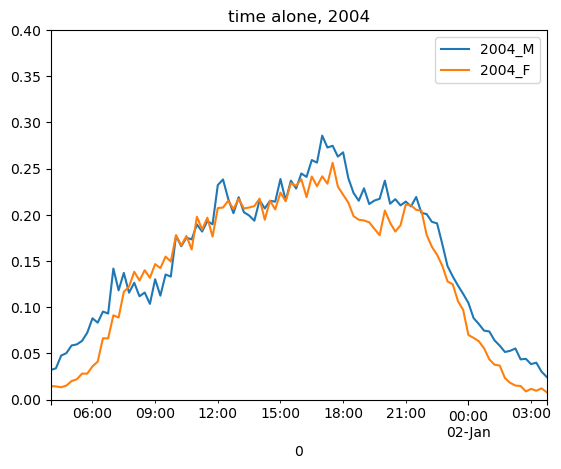

In [33]:
alone_sex[['2004_M', '2004_F']].plot()
plt.ylim((0,0.4))
plt.title("time alone, 2004")

Text(0.5, 1.0, 'time alone, 2024')

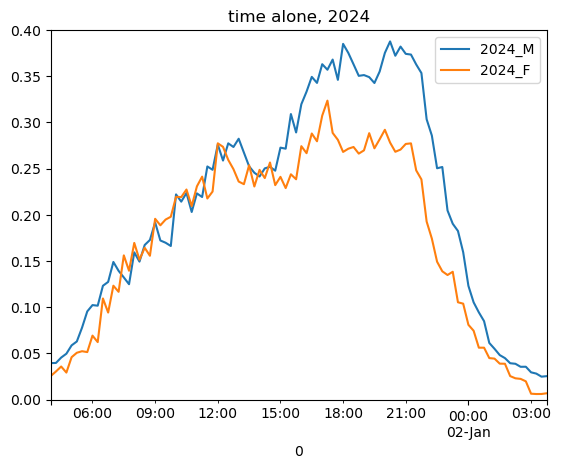

In [34]:
alone_sex[['2024_M', '2024_F']].plot()
plt.ylim((0,0.4))
plt.title("time alone, 2024")

Text(0.5, 1.0, 'M time alone - F time alone')

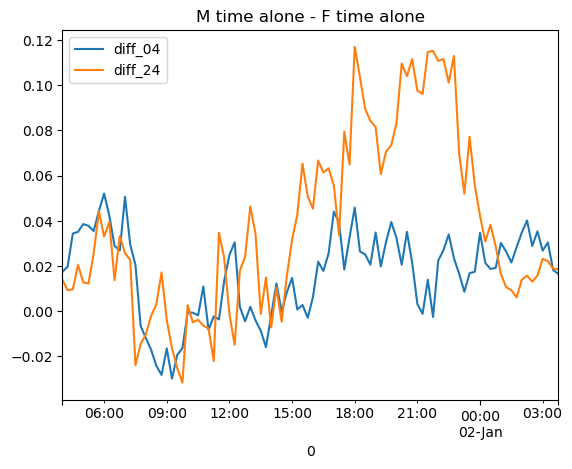

In [35]:
diff = pd.DataFrame()

diff['diff_04'] = (alone_sex['2004_M'] - alone_sex['2004_F'])
diff['diff_24'] = (alone_sex['2024_M'] - alone_sex['2024_F'])

diff.plot()
plt.title("M time alone - F time alone")

(0.0, 0.45)

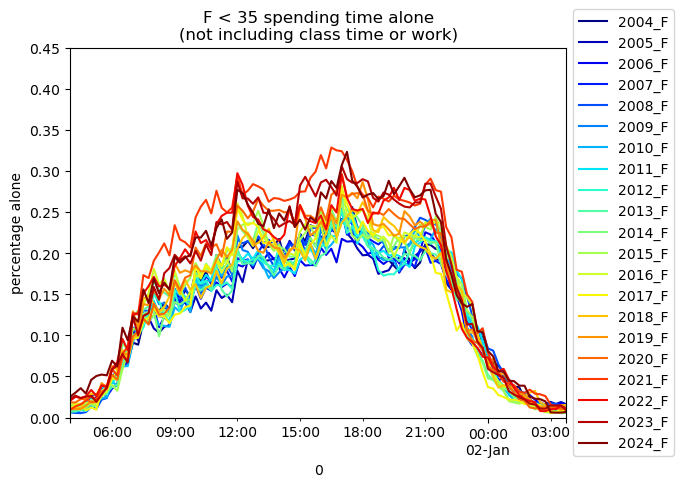

In [36]:
colors = plt.cm.jet(np.linspace(0,1,len(fin_years.T)))
fin_years.plot(color = colors)
plt.legend(loc="center left", bbox_to_anchor = (1,0.5))
plt.title("F < 35 spending time alone\n(not including class time or work)")
plt.ylabel("percentage alone")
plt.ylim((0,0.45))

# video game time and TV time, by hour

In [37]:
activities = ['Television and movies', 'Playing games']

act_who_sum['game_alone'] = ((act_who_sum.alone == 1) & (act_who_sum.description == "Playing games"))*1
act_who_sum['game_w_others'] = ((act_who_sum.alone == 0) & (act_who_sum.description == "Playing games"))*1

act_who_sum['tv_alone'] = ((act_who_sum.alone ==1) & (act_who_sum.description == "Television and movies"))*1
act_who_sum['tv_w_others'] = ((act_who_sum.alone == 0) & (act_who_sum.description == "Television and movies"))*1

In [38]:
act_who_sum[act_who_sum.tv_w_others==1].tail()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,social,description,plot_label,game_alone,game_w_others,tv_alone,tv_w_others
1109032,20241212241381,4,240,1900-01-01 18:00:00,1900-01-01 22:00:00,120303,12,1203,240,0.0,2024,2,1,4,1,220000,35,-1,1.504985e+07,26,1,2,46,1,-1,1,Television and movies,12_Television and movies,0,0,0,1
1109038,20241212241772,5,260,1900-01-01 11:40:00,1900-01-01 16:00:00,120303,12,1203,260,0.0,2024,2,3,7,1,-1,-1,-1,1.161610e+07,25,1,2,43,1,-1,1,Television and movies,12_Television and movies,0,0,0,1
1109053,20241212242171,8,150,1900-01-01 16:30:00,1900-01-01 19:00:00,120303,12,1203,150,0.0,2024,2,1,6,1,36600,10,-1,1.210722e+07,28,1,2,44,1,-1,1,Television and movies,12_Television and movies,0,0,0,1
1109056,20241212242171,11,60,1900-01-01 20:00:00,1900-01-01 21:00:00,120303,12,1203,60,0.0,2024,2,1,6,1,36600,10,-1,1.210722e+07,28,1,2,44,1,-1,1,Television and movies,12_Television and movies,0,0,0,1
1109068,20241212242212,10,112,1900-01-01 18:08:00,1900-01-01 20:00:00,120303,12,1203,112,0.0,2024,2,3,1,2,111600,40,-1,8.531420e+06,27,4,2,43,1,-1,1,Television and movies,12_Television and movies,0,0,0,1


2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022
2023
2024
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022
2023
2024


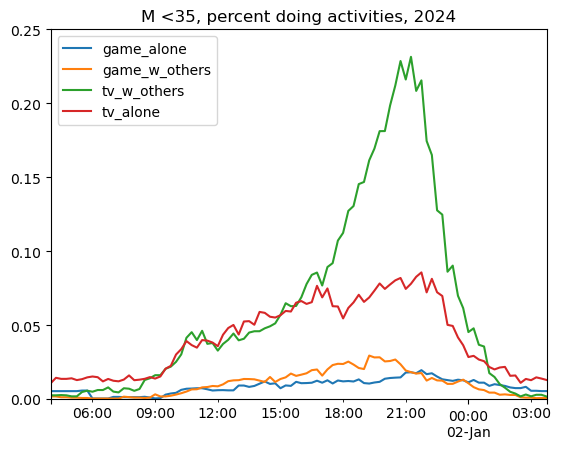

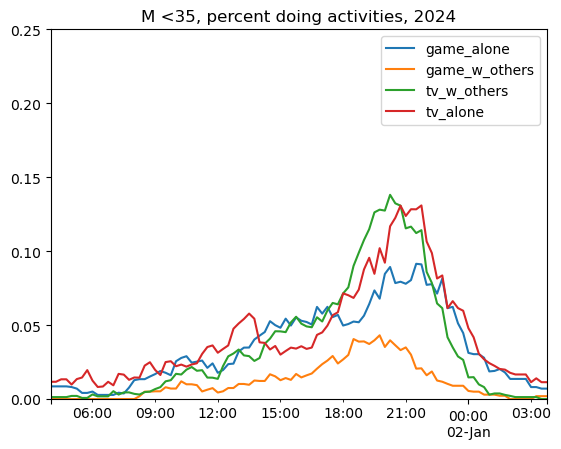

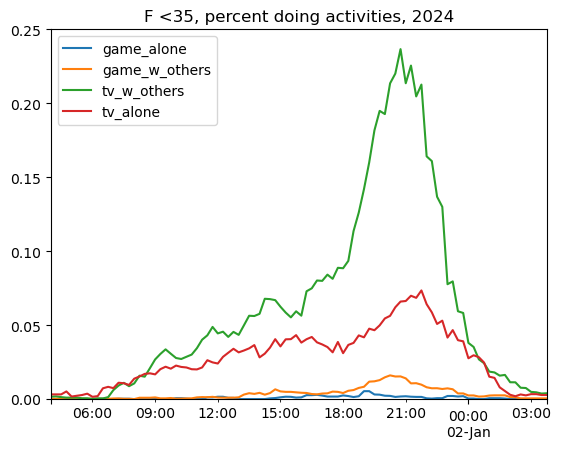

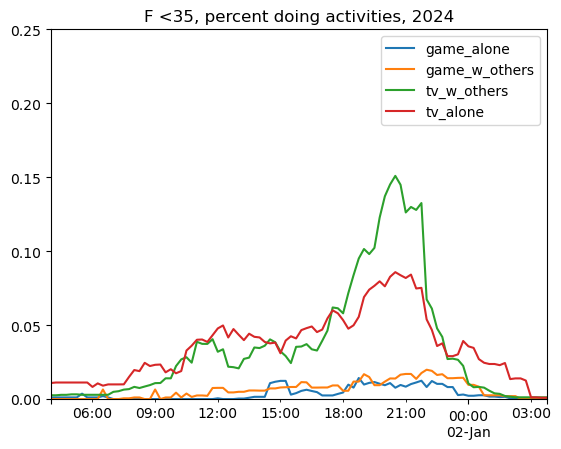

In [39]:

for sex in TESEX_dict: 

    act_year_dfs = {}

    for year in years: 
        
        print(year)
        alone_perc_list = []

        for time in timelist:

            act_year = act_who_sum[(act_who_sum.TUYEAR==year) & (act_who_sum.TESEX==sex)]

            out = act_year[(act_year.TUSTARTTIM <= time) & (act_year.TUSTOPTIME > time)].drop_duplicates('TUCASEID', keep = 'first')

            agg = out[['game_alone', 'game_w_others', 'tv_w_others', 'tv_alone']].apply(lambda x: np.average(x, weights=out.TUFNWGTP), axis=0)
            agg.name = time

            alone_perc_list.append(agg)
        
        act_year_dfs[year] = pd.concat(alone_perc_list, axis = 1)
    
    act_year_dfs[2004].T.plot()
    plt.title(f"{TESEX_dict[sex]} <35, percent doing activities, {year}")
    plt.ylim((0,0.25))

    act_year_dfs[2024].T.plot()
    plt.title(f"{TESEX_dict[sex]} <35, percent doing activities, {year}")
    plt.ylim((0,0.25))

## divide among employed and unemployed and in school/not in school men 

In [40]:
act_who_sum.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,social,description,plot_label,game_alone,game_w_others,tv_alone,tv_w_others
0,20040101040060,1,90,1900-01-01 04:00:00,1900-01-01 05:30:00,120303,12,1203,90,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,1,Television and movies,12_Television and movies,0,0,0,1
1,20040101040060,2,390,1900-01-01 05:30:00,1900-01-01 12:00:00,10101,1,101,390,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,0,Personal Care,1_Personal Care,0,0,0,0
2,20040101040060,3,90,1900-01-01 12:00:00,1900-01-01 13:30:00,10201,1,102,90,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,0,Personal Care,1_Personal Care,0,0,0,0
3,20040101040060,4,30,1900-01-01 13:30:00,1900-01-01 14:00:00,20101,2,201,30,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,0,Household Activities,2_Household Activities,0,0,0,0
4,20040101040060,5,120,1900-01-01 14:00:00,1900-01-01 16:00:00,120101,12,1201,120,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,1,Socializing and Communicating,12_Socializing and Communicating,0,0,0,0


## time alone, broken out by category

In [41]:
act_who_sum['ID'] = act_who_sum['TRTIER1P'].astype(str) + "_" + act_who_sum['description']
act_who_sum.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUACTDUR,alone,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,social,description,plot_label,game_alone,game_w_others,tv_alone,tv_w_others,ID
0,20040101040060,1,90,1900-01-01 04:00:00,1900-01-01 05:30:00,120303,12,1203,90,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,1,Television and movies,12_Television and movies,0,0,0,1,12_Television and movies
1,20040101040060,2,390,1900-01-01 05:30:00,1900-01-01 12:00:00,10101,1,101,390,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,0,Personal Care,1_Personal Care,0,0,0,0,1_Personal Care
2,20040101040060,3,90,1900-01-01 12:00:00,1900-01-01 13:30:00,10201,1,102,90,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,0,Personal Care,1_Personal Care,0,0,0,0,1_Personal Care
3,20040101040060,4,30,1900-01-01 13:30:00,1900-01-01 14:00:00,20101,2,201,30,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,0,Household Activities,2_Household Activities,0,0,0,0,2_Household Activities
4,20040101040060,5,120,1900-01-01 14:00:00,1900-01-01 16:00:00,120101,12,1201,120,0.0,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,1,Socializing and Communicating,12_Socializing and Communicating,0,0,0,0,12_Socializing and Communicating


2004_M_by_TRTIER1P
2004_M_by_plot_label
2004_F_by_TRTIER1P
2004_F_by_plot_label
2024_M_by_TRTIER1P
2024_M_by_plot_label
2024_F_by_TRTIER1P
2024_F_by_plot_label


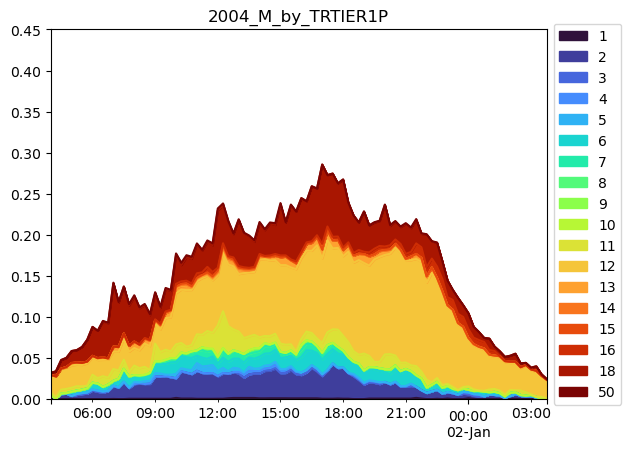

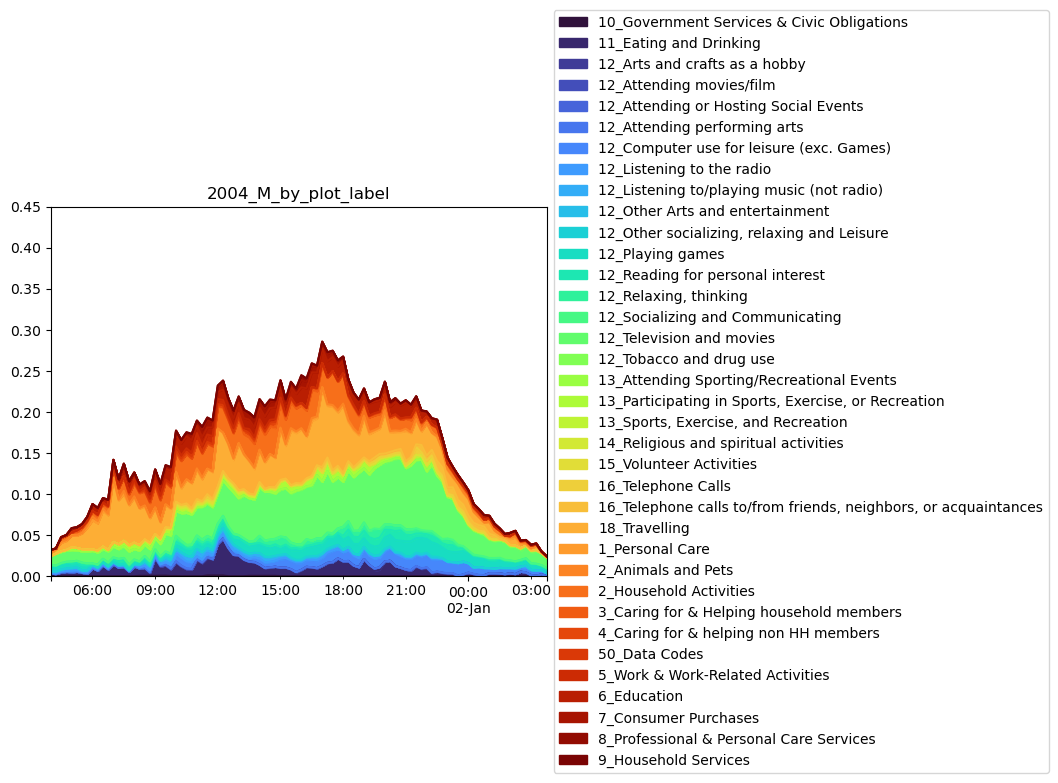

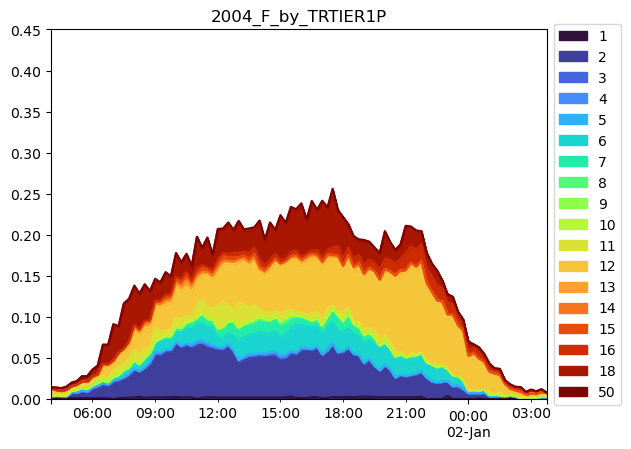

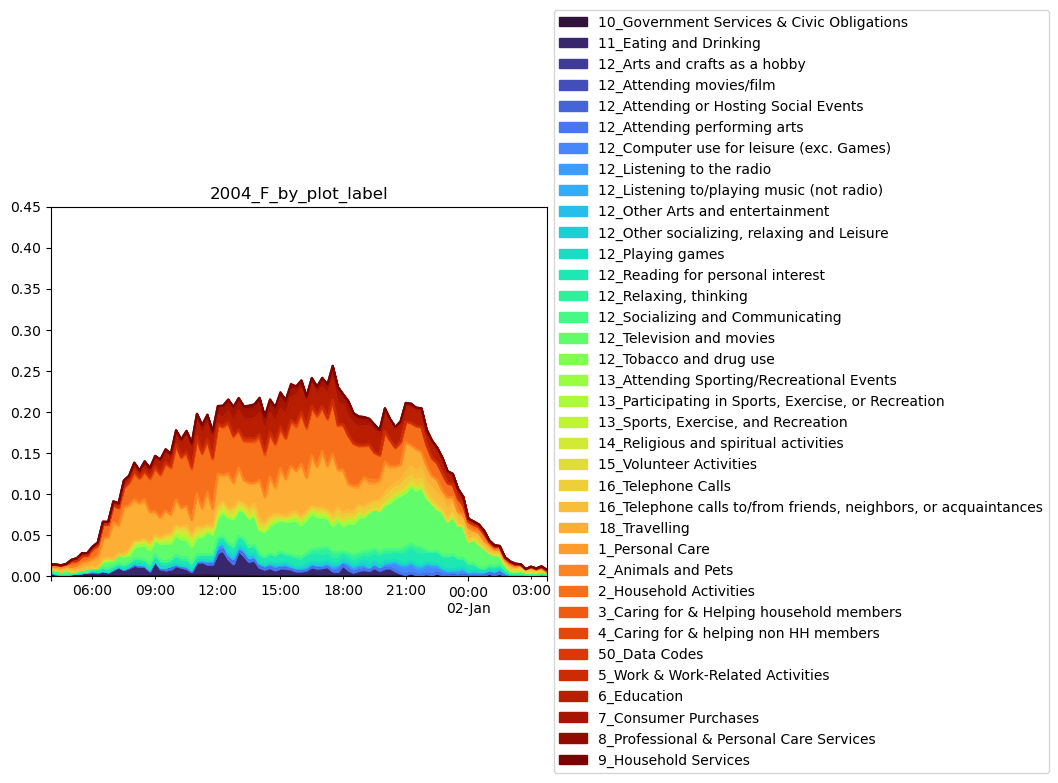

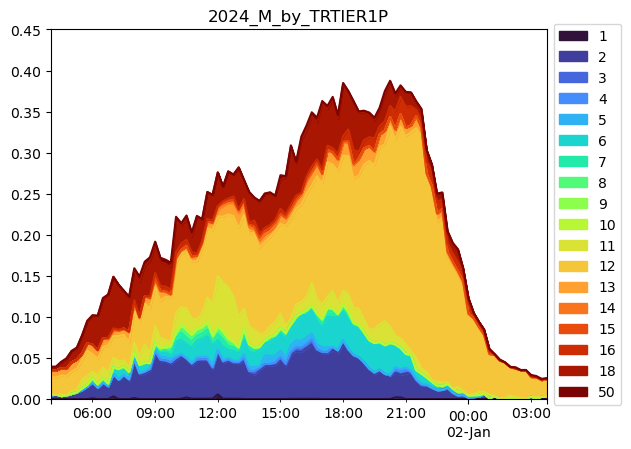

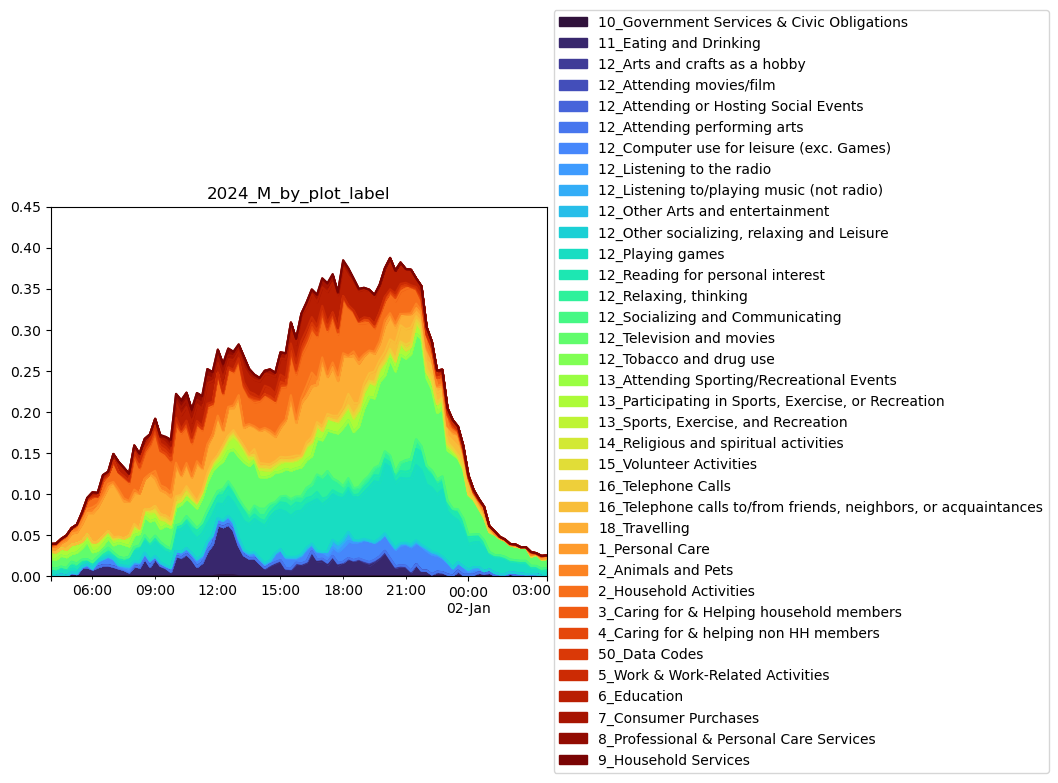

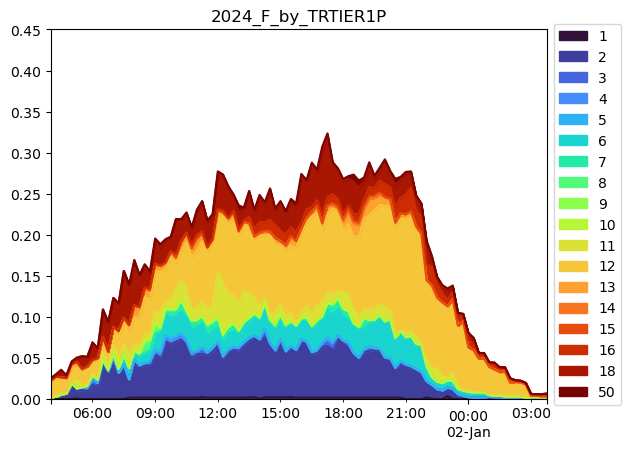

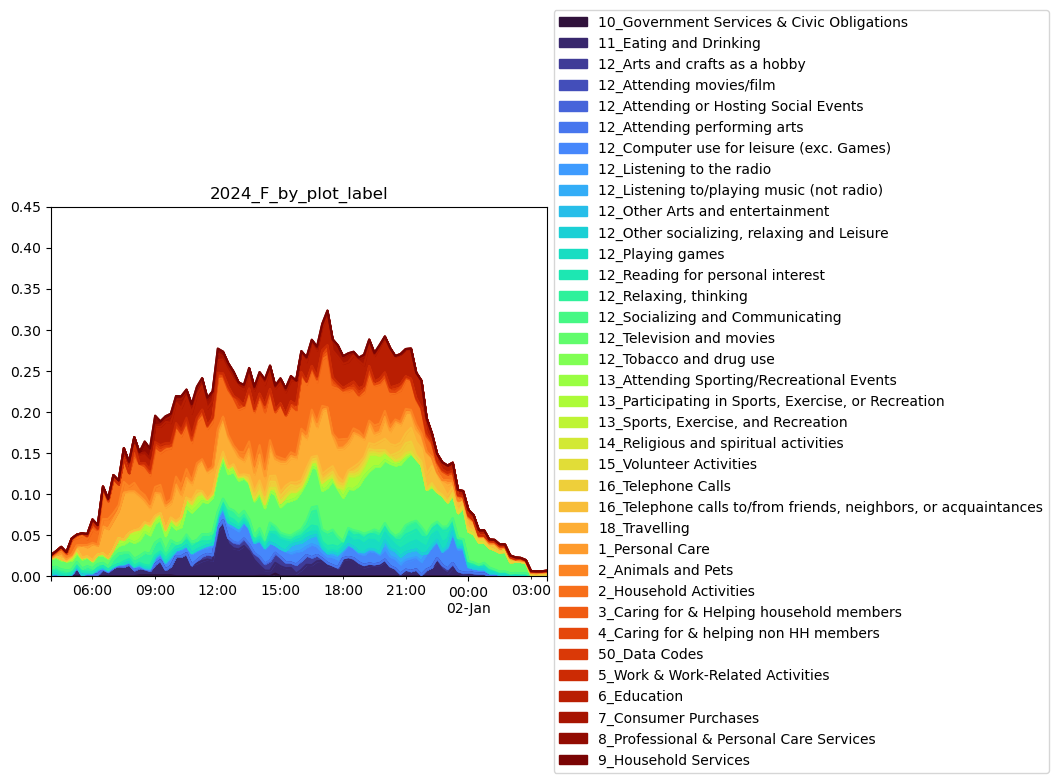

In [42]:
years=[2004, 2024]
long_list = []

with pd.ExcelWriter(processed + 'nb_3_stacked_bar_charts.xlsx') as writer:

    for year in years: 

        for sex in TESEX_dict: 

            for groupby_var in ['TRTIER1P', 'plot_label']:

                pivot_code = pd.pivot_table(act_who_sum, index = ['TUCASEID', 'TUACTIVITY_N', 'TESEX', 'TUSTARTTIM', 'TUSTOPTIME', 'TUYEAR', 'TUFNWGTP'], columns = groupby_var, values = 'alone', aggfunc='mean').fillna(0)
                IDS = pivot_code.columns
                pivot_code = pivot_code.reset_index()
                alone_perc_list = []

                for time in timelist:

                    act_year = pivot_code[(pivot_code.TUYEAR==year) & (pivot_code.TESEX==sex)]
                    
                    out = act_year[(act_year.TUSTARTTIM <= time) & (act_year.TUSTOPTIME > time)].drop_duplicates('TUCASEID', keep = 'first')

                    agg = out[IDS].apply(lambda x: np.average(x, weights=out.TUFNWGTP), axis=0)
                    agg.name = time

                    alone_perc_list.append(agg)

                data = pd.concat(alone_perc_list, axis=1).T

                title = f"{year}_{TESEX_dict[sex]}_by_{groupby_var}"

                data.to_excel(writer, sheet_name = title)

                long = pd.melt(data.reset_index(), id_vars='index', var_name = 'activity', value_name = 'percentage')
                long['year'] = year
                long['sex'] = TESEX_dict[sex]
                long['variable'] = groupby_var

                long_list.append(long)
                
                print(title)

                colors = plt.cm.turbo(np.linspace(0,1,len(data.columns)))
                data.plot.area(color = colors)
                plt.legend(loc="center left", bbox_to_anchor = (1,0.5))
                plt.title(title)
                plt.ylim((0,0.45))
    
final_long = pd.concat(long_list)
final_long.to_csv("nb_3_stacked_bar_charts_long.csv", index = None)

In [43]:
final_long = pd.concat(long_list)
final_long.tail()

,index,activity,percentage,year,sex,variable
3451,1900-01-02 02:45:00,9_Household Services,0.0,2024,F,plot_label
3452,1900-01-02 03:00:00,9_Household Services,0.0,2024,F,plot_label
3453,1900-01-02 03:15:00,9_Household Services,0.0,2024,F,plot_label
3454,1900-01-02 03:30:00,9_Household Services,0.0,2024,F,plot_label
3455,1900-01-02 03:45:00,9_Household Services,0.0,2024,F,plot_label


(0.0, 0.45)

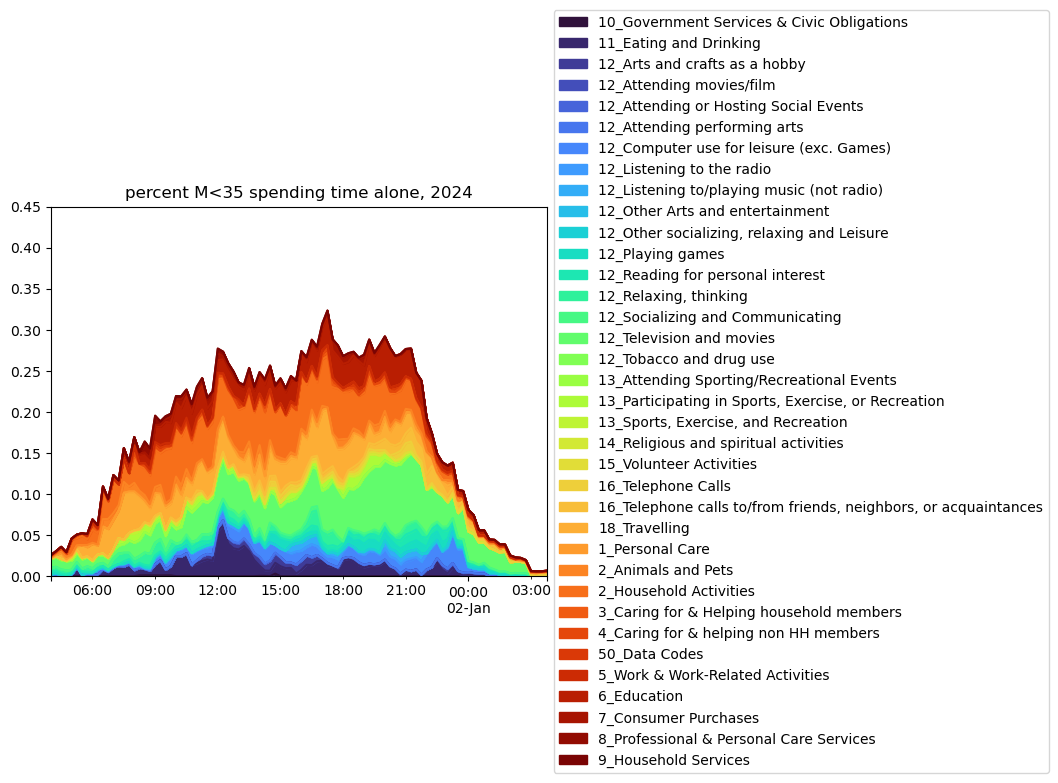

In [44]:
data = pd.concat(alone_perc_list, axis=1).T

colors = plt.cm.turbo(np.linspace(0,1,len(data.columns)))
data.plot.area(color = colors)
plt.legend(loc="center left", bbox_to_anchor = (1,0.5))
plt.title(f"percent M<35 spending time alone, {year}")
plt.ylim((0,0.45))

In [45]:
data.head().reset_index()

plot_label,index,10_Government Services & Civic Obligations,11_Eating and Drinking,12_Arts and crafts as a hobby,12_Attending movies/film,12_Attending or Hosting Social Events,12_Attending performing arts,12_Computer use for leisure (exc. Games),12_Listening to the radio,12_Listening to/playing music (not radio),12_Other Arts and entertainment,"12_Other socializing, relaxing and Leisure",12_Playing games,12_Reading for personal interest,"12_Relaxing, thinking",12_Socializing and Communicating,12_Television and movies,12_Tobacco and drug use,13_Attending Sporting/Recreational Events,"13_Participating in Sports, Exercise, or Recreation","13_Sports, Exercise, and Recreation",14_Religious and spiritual activities,15_Volunteer Activities,16_Telephone Calls,"16_Telephone calls to/from friends, neighbors, or acquaintances",18_Travelling,1_Personal Care,2_Animals and Pets,2_Household Activities,3_Caring for & Helping household members,4_Caring for & helping non HH members,50_Data Codes,5_Work & Work-Related Activities,6_Education,7_Consumer Purchases,8_Professional & Personal Care Services,9_Household Services
0,1900-01-01 04:00:00,0.0,0.000000,0.0,0.0,0.0,0.0,0.001827,0.0,0.0,0.0,0.0,0.001121,0.002346,0.005039,0.0,0.010859,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.001115,0.0,0.000000,0.001520,0.0,0.0,0.001604,0.0,0.0,0.0,0.0,0.0
1,1900-01-01 04:15:00,0.0,0.001104,0.0,0.0,0.0,0.0,0.001827,0.0,0.0,0.0,0.0,0.001121,0.002346,0.005039,0.0,0.011207,0.0,0.0,0.001572,0.0,0.000000,0.0,0.0,0.0,0.001636,0.0,0.001359,0.001520,0.0,0.0,0.001604,0.0,0.0,0.0,0.0,0.0
2,1900-01-01 04:30:00,0.0,0.001104,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.001121,0.000913,0.005039,0.0,0.011207,0.0,0.0,0.001572,0.0,0.000000,0.0,0.0,0.0,0.007575,0.0,0.001359,0.004236,0.0,0.0,0.001604,0.0,0.0,0.0,0.0,0.0
3,1900-01-01 04:45:00,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.001121,0.000913,0.005039,0.0,0.011207,0.0,0.0,0.000000,0.0,0.000477,0.0,0.0,0.0,0.001921,0.0,0.002653,0.004236,0.0,0.0,0.001604,0.0,0.0,0.0,0.0,0.0
4,1900-01-01 05:00:00,0.0,0.001549,0.0,0.0,0.0,0.0,0.000676,0.0,0.0,0.0,0.0,0.001121,0.000913,0.003534,0.0,0.011207,0.0,0.0,0.001307,0.0,0.002936,0.0,0.0,0.0,0.001931,0.0,0.001104,0.017938,0.0,0.0,0.001604,0.0,0.0,0.0,0.0,0.0


## Doing the exact reverse analysis -- what are women doing with others? 

okay so it looks like men are spending more time alone in the evenings -- what are women doing with that time that is with others? 

2004_M_by_TRTIER1P
2004_M_by_plot_label
2004_F_by_TRTIER1P
2004_F_by_plot_label
2024_M_by_TRTIER1P
2024_M_by_plot_label
2024_F_by_TRTIER1P
2024_F_by_plot_label


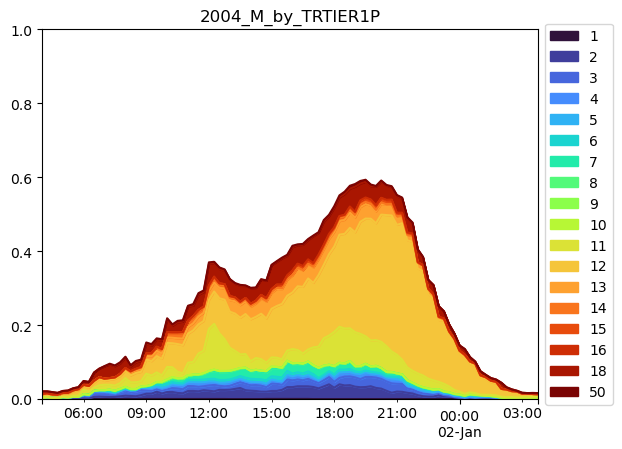

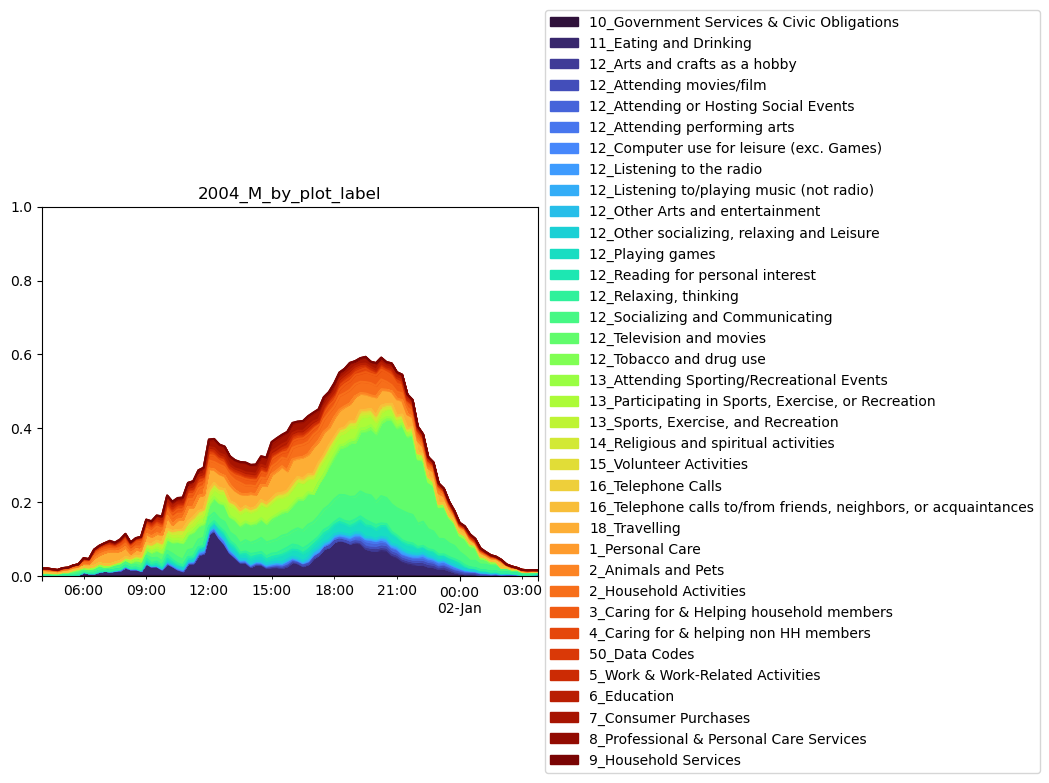

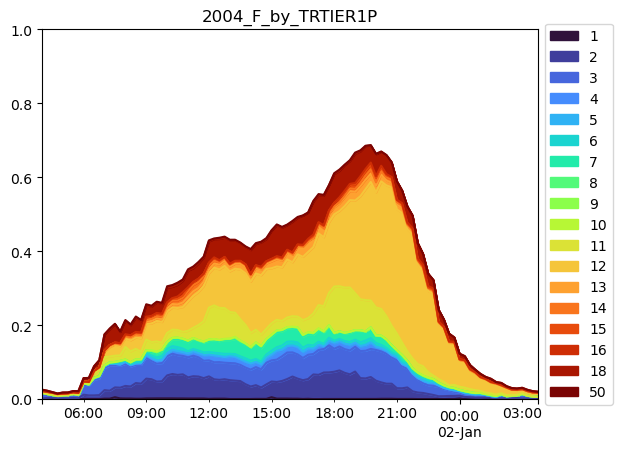

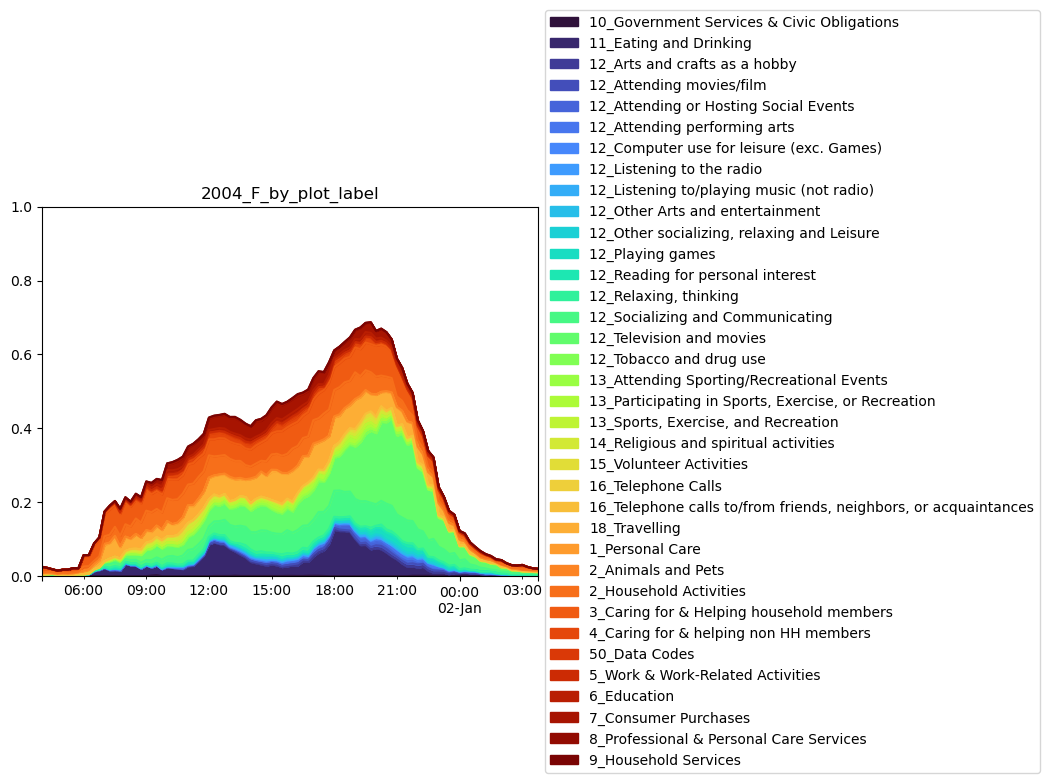

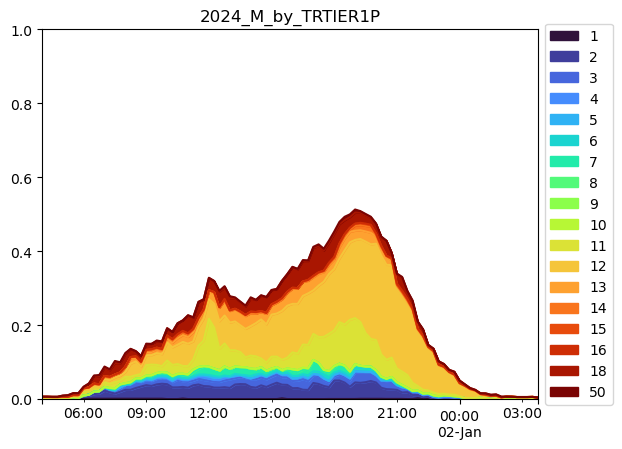

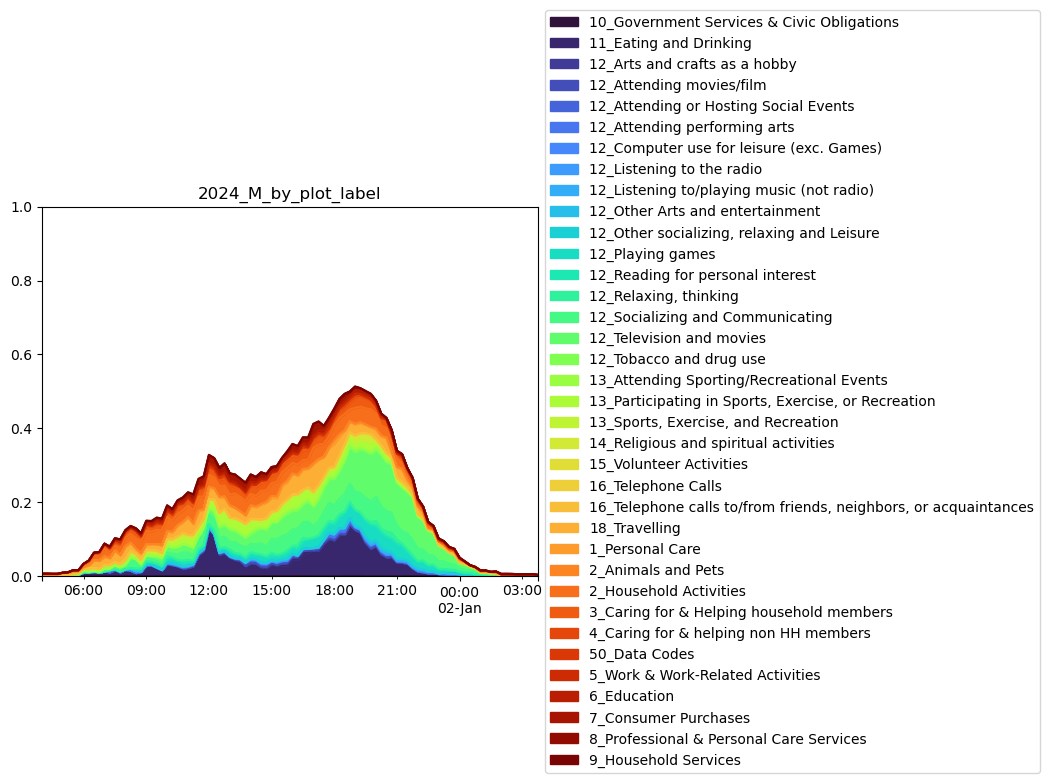

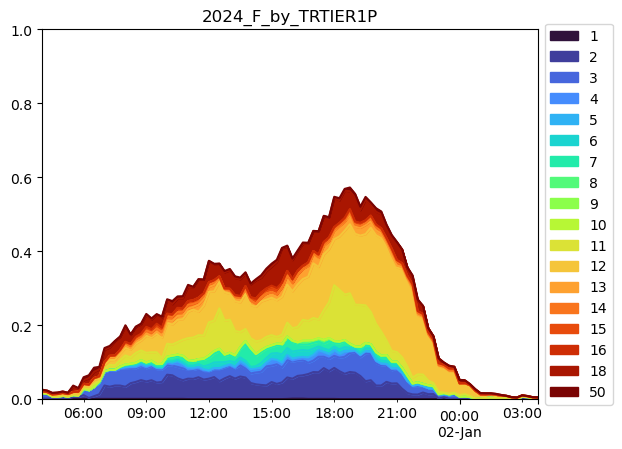

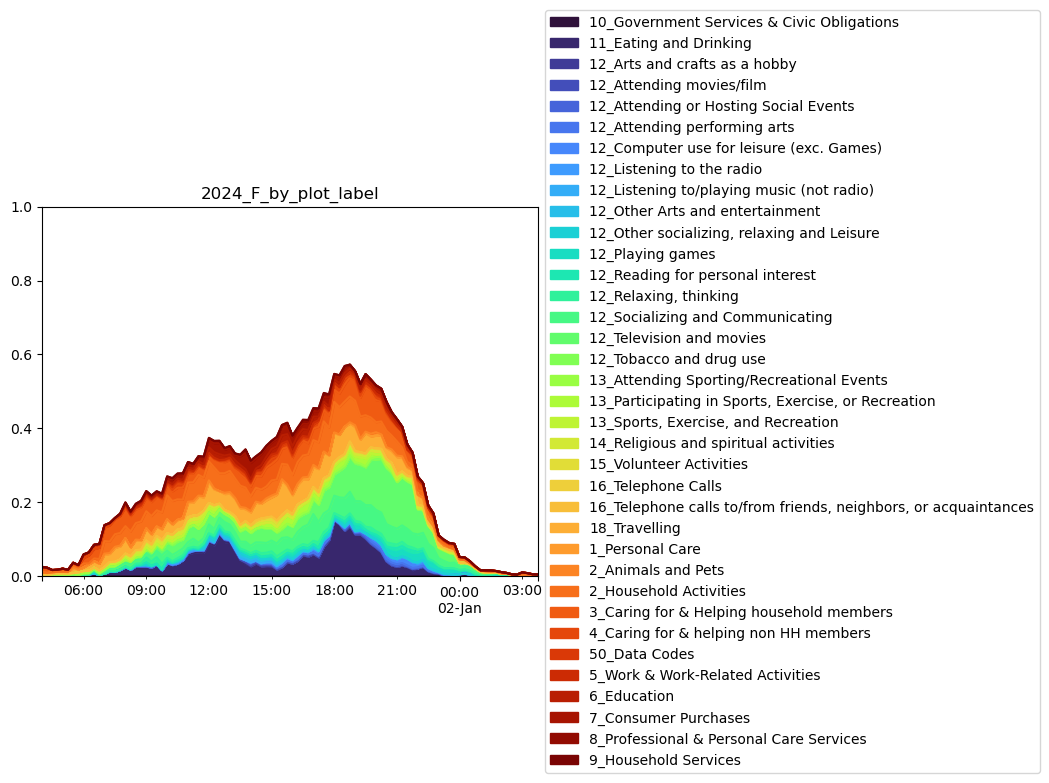

In [46]:
years=[2004, 2024]
TESEX_dict = {1:"M", 2:"F"}

long_list = []

act_who_sum['with_others'] = 1 - act_who_sum['alone']
act_who_sum.loc[act_who_sum.TRCODEP == 60101, 'with_others'] = 0
act_who_sum.loc[act_who_sum.TRTIER2P == 501, 'with_others'] = 0
act_who_sum.loc[act_who_sum.TRTIER2P == 101, 'with_others'] = 0
act_who_sum.loc[act_who_sum.TRTIER2P == 102, 'with_others'] = 0
act_who_sum.loc[act_who_sum.TRTIER2P == 104, 'with_others'] = 0
act_who_sum.loc[act_who_sum.TRCODEP == 500105, 'with_others'] = 0
act_who_sum.loc[act_who_sum.TRCODEP == 500106, 'with_others'] = 0



with pd.ExcelWriter(processed + 'nb_3_stacked_bar_charts_not_alone.xlsx') as writer:

    for year in years: 

        for sex in TESEX_dict: 

            for groupby_var in ['TRTIER1P', 'plot_label']:

                pivot_code = pd.pivot_table(act_who_sum, index = ['TUCASEID', 'TUACTIVITY_N', 'TESEX', 'TUSTARTTIM', 'TUSTOPTIME', 'TUYEAR', 'TUFNWGTP'], columns = groupby_var, values = 'with_others', aggfunc='mean').fillna(0)
                IDS = pivot_code.columns
                pivot_code = pivot_code.reset_index()
                alone_perc_list = []

                for time in timelist:

                    act_year = pivot_code[(pivot_code.TUYEAR==year) & (pivot_code.TESEX==sex)]
                    
                    out = act_year[(act_year.TUSTARTTIM <= time) & (act_year.TUSTOPTIME > time)].drop_duplicates('TUCASEID', keep = 'first')

                    agg = out[IDS].apply(lambda x: np.average(x, weights=out.TUFNWGTP), axis=0)
                    agg.name = time

                    alone_perc_list.append(agg)

                data = pd.concat(alone_perc_list, axis=1).T

                title = f"{year}_{TESEX_dict[sex]}_by_{groupby_var}"

                data.to_excel(writer, sheet_name = title)

                long = pd.melt(data.reset_index(), id_vars='index', var_name = 'activity', value_name = 'percentage')
                long['year'] = year
                long['sex'] = TESEX_dict[sex]
                long['variable'] = groupby_var

                long_list.append(long)
                
                print(title)

                colors = plt.cm.turbo(np.linspace(0,1,len(data.columns)))
                data.plot.area(color = colors)
                plt.legend(loc="center left", bbox_to_anchor = (1,0.5))
                plt.title(title)
                plt.ylim((0,1))
    
final_long = pd.concat(long_list)
final_long.to_csv("nb_3_stacked_bar_charts_long_not_alone.csv", index = None)

In [47]:
years = range(2004, 2025)

with_others = []

for sex in TESEX_dict:
    print(sex)
    alone_yr_dfs = {}

    for year in years: 

        alone_perc_list = []

        for time in timelist:

            act_year = act_who_sum[(act_who_sum.TUYEAR==year) & (act_who_sum.TESEX==sex)]
            alone_perc_list.append([time,get_activity_time(act_year, time, var = 'with_others')])
        
        alone_yr_dfs[year] = pd.DataFrame(alone_perc_list).set_index(0)

    fin_years = pd.concat([alone_yr_dfs[index] for index in alone_yr_dfs], axis = 1)
    fin_years.columns = pd.Series(years).astype(str) + "_" + TESEX_dict[sex]

    with_others.append(fin_years)

with_others_sex = pd.concat(with_others, axis=1)
with_others_sex.head()

1
2


,2004_M,2005_M,2006_M,2007_M,2008_M,2009_M,2010_M,2011_M,2012_M,2013_M,2014_M,2015_M,2016_M,2017_M,2018_M,2019_M,2020_M,2021_M,2022_M,2023_M,2024_M,2004_F,2005_F,2006_F,2007_F,2008_F,2009_F,2010_F,2011_F,2012_F,2013_F,2014_F,2015_F,2016_F,2017_F,2018_F,2019_F,2020_F,2021_F,2022_F,2023_F,2024_F
0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1900-01-01 04:00:00,0.020933,0.017735,0.012909,0.015017,0.018730,0.027585,0.012408,0.022293,0.009007,0.010316,0.010732,0.012337,0.011100,0.010605,0.008899,0.020533,0.012739,0.013942,0.002628,0.020039,0.006602,0.025485,0.017325,0.022753,0.023707,0.020884,0.024184,0.020986,0.021344,0.019785,0.018015,0.026063,0.024007,0.021880,0.027934,0.032117,0.023849,0.022426,0.020313,0.013104,0.015449,0.025378
1900-01-01 04:15:00,0.020933,0.019445,0.014643,0.015406,0.019138,0.024030,0.012902,0.023251,0.008524,0.009869,0.009381,0.011964,0.013095,0.011807,0.008838,0.021029,0.012739,0.015021,0.001947,0.021482,0.006602,0.022661,0.018198,0.020386,0.022428,0.022425,0.022057,0.019716,0.019709,0.018953,0.016605,0.026248,0.026103,0.020968,0.024193,0.026477,0.020419,0.020387,0.020586,0.014408,0.012775,0.022966
1900-01-01 04:30:00,0.018915,0.020358,0.015438,0.016899,0.019147,0.025720,0.014820,0.021824,0.009769,0.009617,0.009573,0.010319,0.017149,0.008901,0.005179,0.022186,0.015924,0.017293,0.008064,0.024975,0.006265,0.018851,0.018016,0.021355,0.019007,0.018253,0.019011,0.017263,0.019345,0.013880,0.016603,0.024551,0.018415,0.022546,0.016613,0.024420,0.014426,0.016310,0.017846,0.012494,0.008053,0.016686
1900-01-01 04:45:00,0.016803,0.020239,0.015377,0.017758,0.022428,0.025024,0.013166,0.021554,0.011509,0.011542,0.017450,0.010319,0.015593,0.009259,0.008868,0.026039,0.015924,0.016638,0.002855,0.025179,0.006265,0.015039,0.017249,0.021240,0.016651,0.018200,0.019215,0.013076,0.019477,0.013557,0.015482,0.020917,0.019960,0.022220,0.020050,0.020838,0.012800,0.013252,0.016881,0.012585,0.008351,0.017616
1900-01-01 05:00:00,0.021965,0.022627,0.019929,0.024340,0.029154,0.027948,0.014356,0.019493,0.014998,0.017461,0.023042,0.019741,0.014384,0.019067,0.006931,0.025456,0.018047,0.019046,0.017771,0.025221,0.009379,0.017685,0.022287,0.020069,0.017132,0.022132,0.019296,0.016792,0.018753,0.017208,0.018157,0.024376,0.021277,0.020779,0.024001,0.027754,0.015535,0.015291,0.022687,0.020569,0.010152,0.020470


Text(0.5, 1.0, 'time with others, 2004')

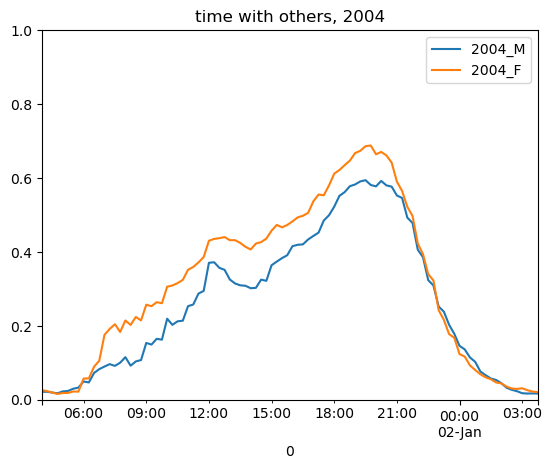

In [48]:
with_others_sex[['2004_M', '2004_F']].plot()
plt.ylim((0,1))
plt.title("time with others, 2004")

Text(0.5, 1.0, 'time with others, 2024')

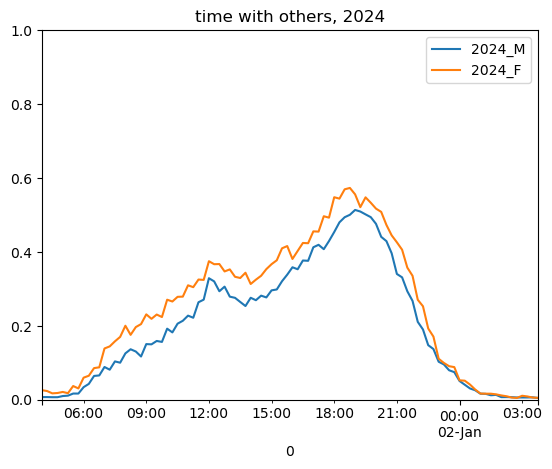

In [49]:
with_others_sex[['2024_M', '2024_F']].plot()
plt.ylim((0,1))
plt.title("time with others, 2024")

Text(0.5, 1.0, 'F time with others - M time with others')

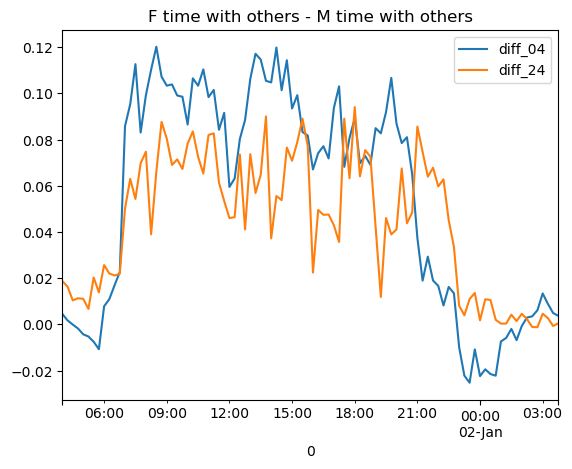

In [50]:
diff = pd.DataFrame()

diff['diff_04'] = (with_others_sex['2004_F'] - with_others_sex['2004_M'])
diff['diff_24'] = (with_others_sex['2024_F'] - with_others_sex['2024_M'])
diff['M'] = (with_others_sex['2024_M'] - with_others_sex['2004_M'])
diff['F'] = (with_others_sex['2024_F'] - with_others_sex['2004_F'])


diff[['diff_04', 'diff_24']].plot()
plt.title("F time with others - M time with others")

Text(0.5, 1.0, '2024 time with others - 2004 time with others')

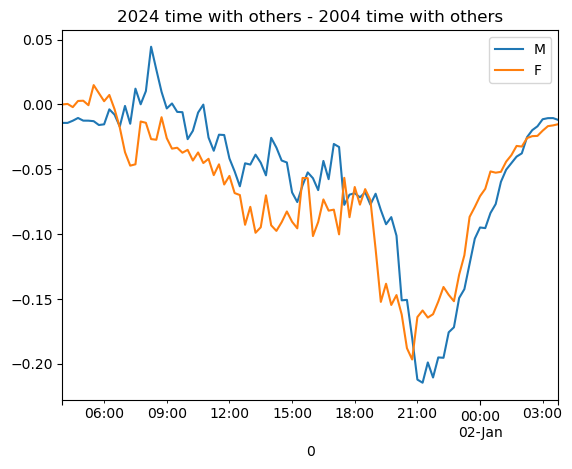

In [51]:
diff[['M', 'F']].plot()
plt.title("2024 time with others - 2004 time with others")

In [52]:
with pd.ExcelWriter(processed + 'nb_3_with_others_hours_per_week_by_sex.xlsx') as writer:

    f = weighted_average_pivot(act_who_sum[act_who_sum.with_others==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['TRCODEP'], 'TUACTDUR24')

    f.to_excel(writer, sheet_name = var, index =None)

In [53]:
a_2004 = f.pivot_table(index = 'TRCODEP', columns = 'TESEX', values = 2004)
a_2024 = f.pivot_table(index = 'TRCODEP', columns = 'TESEX', values = 2024)

In [54]:
a_2004['diff'] = a_2004[2] - a_2004[1]
print(a_2004.sum())
a_2004.sort_values(by = 'diff', ascending=False).head(10)

TESEX
1       43.717755
2       52.657390
diff     8.899353
dtype: float64


TESEX,1,2,diff
TRCODEP,,,
30101,0.667395,3.395088,2.727694
20201,0.547233,1.729751,1.182518
20101,0.344788,1.352912,1.008124
30103,0.569673,1.445148,0.875475
70104,1.213419,1.825751,0.612333
20102,0.064132,0.512635,0.448503
180381,0.137683,0.562325,0.424642
120101,5.186595,5.571331,0.384736
70101,0.265665,0.566866,0.301201


In [55]:
a_2024['diff'] = a_2024[2] - a_2024[1]
print(a_2024.sum())
a_2024.sort_values(by = 'diff', ascending=False).head(10)

TESEX
1       34.096044
2       41.458709
diff     7.578723
dtype: float64


TESEX,1,2,diff
TRCODEP,,,
30101,0.608449,2.061837,1.453388
20201,1.158362,2.333709,1.175347
20101,0.536814,1.542033,1.005218
30103,0.636017,1.207768,0.571751
70104,0.557731,1.064811,0.507079
180381,0.093727,0.525278,0.431551
110101,5.401313,5.784444,0.383132
150402,0.022583,0.355471,0.332889
120301,0.522418,0.847070,0.324652


Text(0.5, 1.0, 'difference in time spent with others (female - male)')

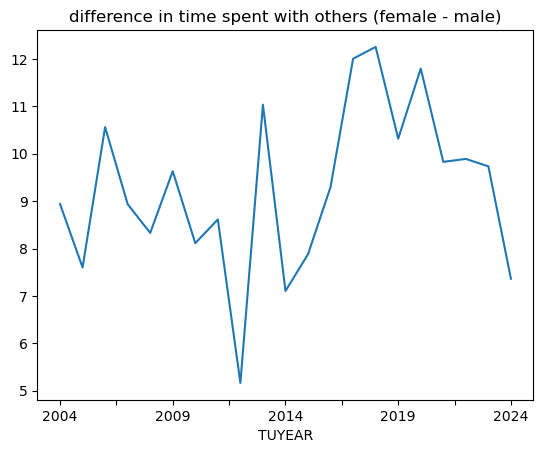

In [56]:
d = f.drop(['TRCODEP', 'raw_change'], axis=1).groupby('TESEX').sum().T
d['difference'] = d[2]-d[1]
d.difference.plot()
plt.title("difference in time spent with others (female - male)")

Text(0.5, 1.0, 'hours spent with others each week')

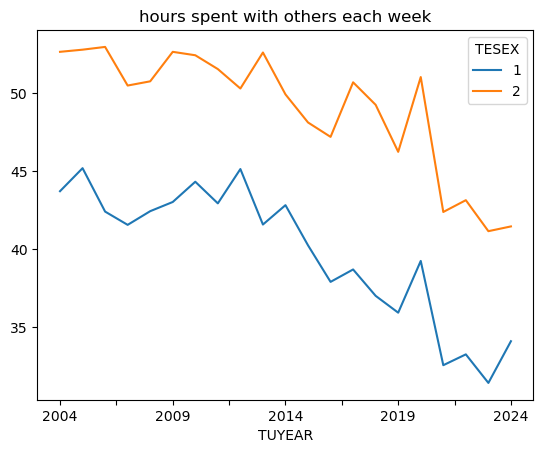

In [57]:
d[[1,2]].plot()
plt.title("hours spent with others each week")

In [58]:
f.sort_values('raw_change', ascending=True).head(10)

TUYEAR,TRCODEP,TESEX,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,raw_change
374,120303,2,10.631892,10.391532,9.642949,9.412354,9.948566,10.854556,10.279097,9.576041,9.860159,10.026898,9.653610,9.204222,8.435042,8.643023,9.110785,8.791820,9.236290,7.647972,7.121469,7.493954,6.098529,-4.533363
373,120303,1,10.602658,9.945736,9.575484,9.709950,9.750298,10.405106,9.487706,9.552933,10.588185,8.871812,9.965399,9.530204,8.114015,7.803045,7.400393,7.777706,8.921656,7.321732,7.534545,5.779071,6.288350,-4.314308
361,120101,2,5.571331,5.170850,5.419975,5.633112,5.136838,5.221137,5.021501,5.293832,5.192311,5.384863,4.978416,4.929738,4.028728,4.979214,4.449030,3.929865,5.038311,4.139269,3.776902,3.815142,3.819862,-1.751469
360,120101,1,5.186595,5.248920,4.730648,4.259388,5.103628,4.321069,5.341829,4.445108,5.102467,4.811045,5.243335,4.373346,4.716715,4.297512,4.194912,4.023760,4.703698,3.572935,3.355988,3.623830,3.700767,-1.485828
67,30101,2,3.395088,3.059708,3.098747,2.942579,2.915397,2.936893,2.865500,2.818823,2.624805,2.637665,2.935178,2.576753,2.573245,2.449582,2.848047,2.332451,3.131448,2.263633,1.922215,2.069207,2.061837,-1.333251
267,70104,2,1.825751,2.154428,2.217064,1.701861,1.848901,1.786330,1.487633,1.217536,1.554236,1.721246,1.633061,1.448931,1.325087,1.445728,1.194317,1.338174,0.917159,1.214888,0.918554,1.112138,1.064811,-0.760941
266,70104,1,1.213419,1.151747,0.842332,0.969803,0.827101,0.917171,0.993063,0.993436,1.032217,0.930254,0.692797,0.863401,0.750279,0.786084,0.544584,0.541489,0.614791,0.544202,0.525687,0.521172,0.557731,-0.655687
364,120201,2,0.710720,0.656771,0.662099,0.772360,0.685829,0.721103,0.663409,0.983040,0.989560,0.657909,0.618065,0.462625,0.670498,0.614420,0.755332,0.493069,0.506626,0.376029,0.476716,0.408976,0.196591,-0.514129
422,130103,1,0.448478,0.540526,0.494164,0.378692,0.390462,0.572374,0.409713,0.563808,0.474835,0.387856,0.433188,0.292814,0.303749,0.415748,0.358289,0.145451,0.206582,0.207980,0.221456,0.316139,0.032025,-0.416453
690,181201,2,0.631259,0.597421,0.576654,0.447821,0.586797,0.654401,0.582738,0.457303,0.504723,0.504382,0.499501,0.458587,0.328444,0.399522,0.394061,0.374594,0.342032,0.337882,0.156775,0.285048,0.215179,-0.416080


2004_M_by_TRTIER1P
2024_M_by_TRTIER1P
2004_F_by_TRTIER1P
2024_F_by_TRTIER1P


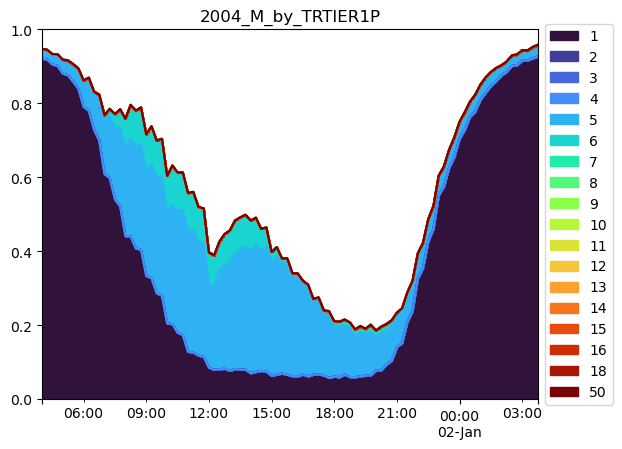

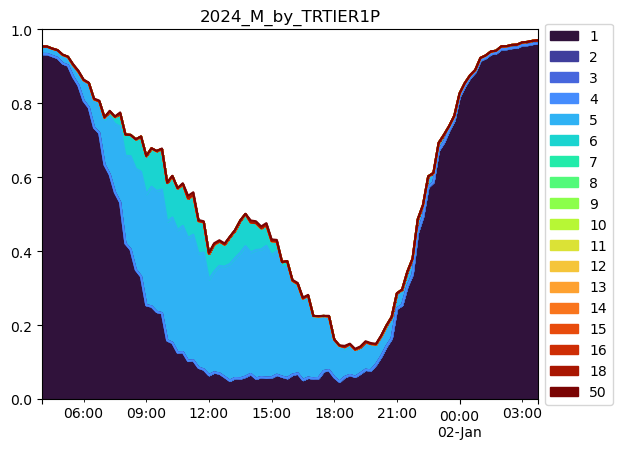

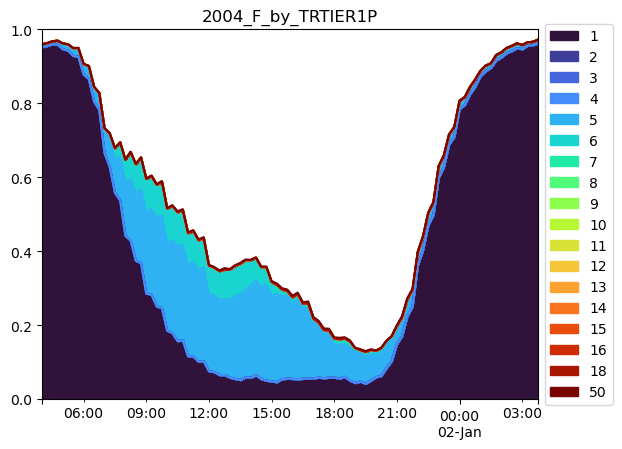

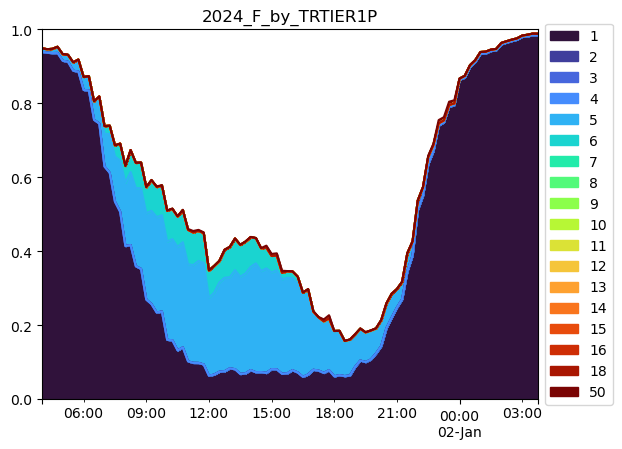

In [59]:
years=[2004, 2024]
TESEX_dict = {1:"M", 2:"F"}

act_who_sum['no_info']=0

act_who_sum.loc[act_who_sum.TRCODEP == 60101, 'no_info'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 501, 'no_info'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 101, 'no_info'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 102, 'no_info'] = 1
act_who_sum.loc[act_who_sum.TRTIER2P == 104, 'no_info'] = 1
act_who_sum.loc[act_who_sum.TRCODEP == 500105, 'no_info'] = 1
act_who_sum.loc[act_who_sum.TRCODEP == 500106, 'no_info'] = 1

with pd.ExcelWriter(processed + 'nb_3_stacked_bar_charts_no_info.xlsx') as writer:

    for sex in TESEX_dict: 
             
        for year in years: 

            for groupby_var in ['TRTIER1P']:

                pivot_code = pd.pivot_table(act_who_sum, index = ['TUCASEID', 'TUACTIVITY_N', 'TESEX', 'TUSTARTTIM', 'TUSTOPTIME', 'TUYEAR', 'TUFNWGTP'], columns = groupby_var, values = 'no_info', aggfunc='mean').fillna(0)
                IDS = pivot_code.columns
                pivot_code = pivot_code.reset_index()
                alone_perc_list = []

                for time in timelist:

                    act_year = pivot_code[(pivot_code.TUYEAR==year) & (pivot_code.TESEX==sex)]
                    
                    out = act_year[(act_year.TUSTARTTIM <= time) & (act_year.TUSTOPTIME > time)].drop_duplicates('TUCASEID', keep = 'first')

                    agg = out[IDS].apply(lambda x: np.average(x, weights=out.TUFNWGTP), axis=0)
                    agg.name = time

                    alone_perc_list.append(agg)

                data = pd.concat(alone_perc_list, axis=1).T

                title = f"{year}_{TESEX_dict[sex]}_by_{groupby_var}"

                data.to_excel(writer, sheet_name = title)

                long = pd.melt(data.reset_index(), id_vars='index', var_name = 'activity', value_name = 'percentage')
                long['year'] = year
                long['sex'] = TESEX_dict[sex]
                long['variable'] = groupby_var

                long_list.append(long)
                
                print(title)

                colors = plt.cm.turbo(np.linspace(0,1,len(data.columns)))
                data.plot.area(color = colors)
                plt.legend(loc="center left", bbox_to_anchor = (1,0.5))
                plt.title(title)
                plt.ylim((0,1))
    
final_long = pd.concat(long_list)
final_long.to_csv("nb_3_stacked_bar_charts_long_no_info.csv", index = None)

In [60]:
years = range(2004, 2025)

no_info = []

for sex in TESEX_dict:
    print(sex)
    alone_yr_dfs = {}

    for year in years: 

        alone_perc_list = []

        for time in timelist:

            act_year = act_who_sum[(act_who_sum.TUYEAR==year) & (act_who_sum.TESEX==sex)]
            alone_perc_list.append([time,get_activity_time(act_year, time, var = 'no_info')])
        
        alone_yr_dfs[year] = pd.DataFrame(alone_perc_list).set_index(0)

    fin_years = pd.concat([alone_yr_dfs[index] for index in alone_yr_dfs], axis = 1)
    fin_years.columns = pd.Series(years).astype(str) + "_" + TESEX_dict[sex]

    no_info.append(fin_years)

no_info_sex = pd.concat(no_info, axis=1)
no_info_sex.head()

1
2


,2004_M,2005_M,2006_M,2007_M,2008_M,2009_M,2010_M,2011_M,2012_M,2013_M,2014_M,2015_M,2016_M,2017_M,2018_M,2019_M,2020_M,2021_M,2022_M,2023_M,2024_M,2004_F,2005_F,2006_F,2007_F,2008_F,2009_F,2010_F,2011_F,2012_F,2013_F,2014_F,2015_F,2016_F,2017_F,2018_F,2019_F,2020_F,2021_F,2022_F,2023_F,2024_F
0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1900-01-01 04:00:00,0.947146,0.967465,0.952634,0.958010,0.957774,0.956468,0.964300,0.958732,0.964523,0.968693,0.962488,0.958443,0.957441,0.966903,0.959960,0.953967,0.949045,0.953660,0.979441,0.944942,0.953982,0.959991,0.971130,0.963865,0.968628,0.972813,0.964026,0.966825,0.965166,0.970218,0.974890,0.960921,0.963838,0.962615,0.960941,0.957397,0.966027,0.959225,0.970170,0.966368,0.962060,0.949191
1900-01-01 04:15:00,0.945271,0.966302,0.947490,0.956387,0.952739,0.955887,0.963876,0.957201,0.962881,0.965586,0.963604,0.958789,0.947081,0.960051,0.959673,0.950790,0.946921,0.950726,0.980053,0.931604,0.953822,0.963165,0.971812,0.964337,0.971040,0.972031,0.962396,0.973254,0.965915,0.973091,0.975931,0.960485,0.963034,0.962296,0.960638,0.961020,0.969457,0.961264,0.965831,0.960396,0.960582,0.946700
1900-01-01 04:30:00,0.933533,0.959610,0.950659,0.935388,0.953776,0.959579,0.961688,0.954859,0.959081,0.959678,0.951445,0.957686,0.944723,0.964404,0.959676,0.929700,0.940552,0.941983,0.961916,0.925526,0.948341,0.967889,0.970888,0.968789,0.969583,0.976378,0.968846,0.974093,0.965972,0.976790,0.971989,0.961256,0.972197,0.960819,0.967075,0.964057,0.975100,0.961264,0.966081,0.963749,0.968340,0.947585
1900-01-01 04:45:00,0.933011,0.958828,0.948358,0.935693,0.942766,0.955567,0.958787,0.957644,0.957716,0.954441,0.946186,0.955873,0.946793,0.962269,0.955566,0.926771,0.942675,0.937984,0.962407,0.918066,0.944139,0.969862,0.965528,0.968600,0.972913,0.975236,0.967845,0.976157,0.962932,0.978384,0.971622,0.964317,0.967962,0.960203,0.971021,0.956205,0.972980,0.964322,0.962555,0.961638,0.966137,0.953215
1900-01-01 05:00:00,0.919542,0.947436,0.924340,0.929132,0.930404,0.943695,0.950648,0.954377,0.958385,0.951985,0.936315,0.930071,0.944596,0.941733,0.941247,0.908537,0.923567,0.926044,0.942583,0.891523,0.932021,0.962350,0.955093,0.953465,0.966767,0.964735,0.957245,0.966214,0.960484,0.970103,0.961186,0.953715,0.962118,0.961522,0.963716,0.943191,0.964586,0.966361,0.951360,0.945862,0.963585,0.933709


Text(0.5, 1.0, 'no info, 2004')

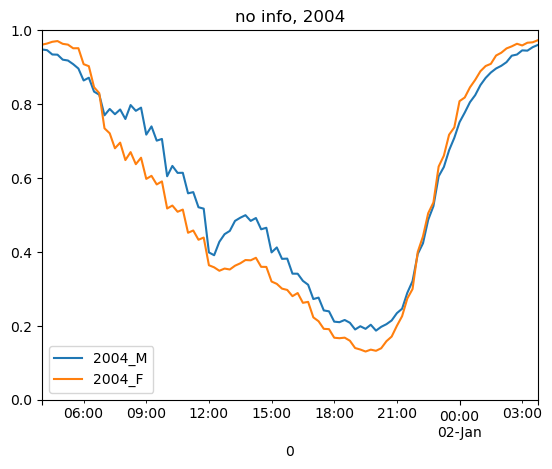

In [61]:
no_info_sex[['2004_M', '2004_F']].plot()
plt.ylim((0,1))
plt.title('no info, 2004')

Text(0.5, 1.0, 'no info, 2024')

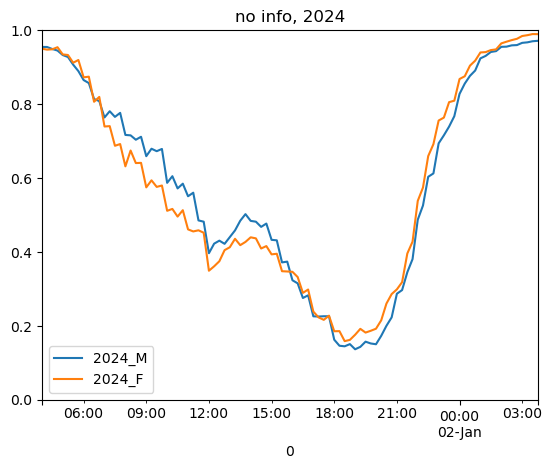

In [62]:
no_info_sex[['2024_M', '2024_F']].plot()
plt.ylim((0,1))
plt.title('no info, 2024')

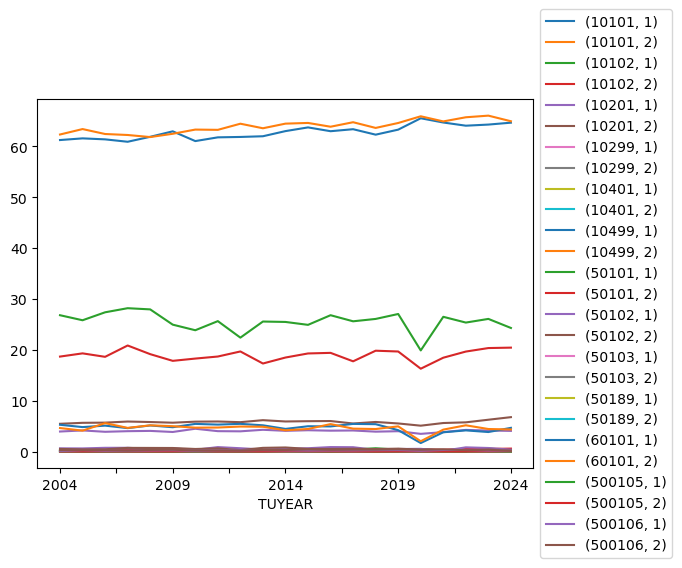

In [63]:
f = weighted_average_pivot(act_who_sum[act_who_sum.no_info==1], sum_resp, 'TUFNWGTP', ['TUYEAR'], ['TESEX'], ['TRCODEP'], 'TUACTDUR24')
f.set_index(['TRCODEP', 'TESEX']).drop('raw_change', axis=1).T.plot()
plt.legend(loc="center left", bbox_to_anchor = (1,0.5))

Text(0.5, 1.0, 'difference in time with no information (female - male)')

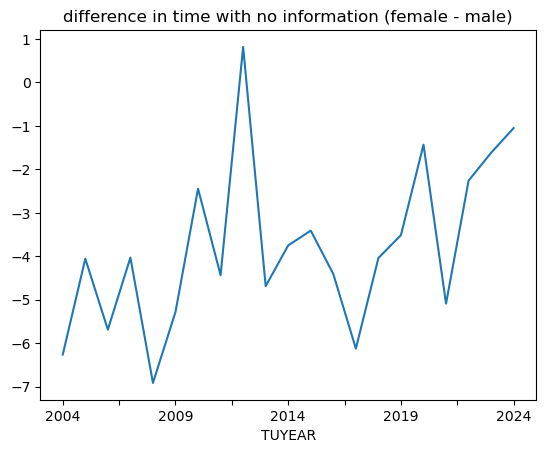

In [64]:
d = f.drop(['TRCODEP', 'raw_change'], axis=1).groupby('TESEX').sum().T
d['difference'] = d[2]-d[1]
d.difference.plot()
plt.title("difference in time with no information (female - male)")

<Axes: xlabel='TUYEAR'>

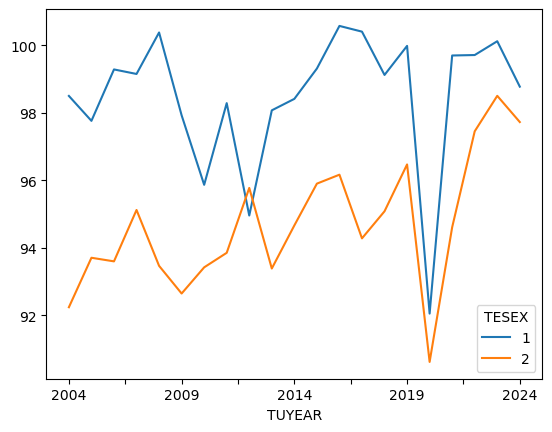

In [65]:
d[[1,2]].plot()

In [66]:
f[['TRCODEP', 'TESEX', 'raw_change']].sort_values('raw_change', ascending=False)

TUYEAR,TRCODEP,TESEX,raw_change
0,10101,1,3.414632
1,10101,2,2.605955
13,50101,2,1.758261
5,10201,2,1.305189
3,10102,2,0.435520
2,10102,1,0.152374
4,10201,1,0.124882
24,500106,1,0.109688
23,500105,2,0.054858
18,50189,1,0.036799
